# Actividad 6 | Evaluación y validación de riesgo crediticio

## ETAPA 1. Auditoría inicial de datos

*Fuente: South German Credit (UCI).*

### 1.1 | Preparación del entorno

*Librerías, semilla y directorio de resultados.*

In [1]:
import hashlib
import io
import json
import sys
import zipfile
from pathlib import Path
from urllib.request import Request, urlopen

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEMILLA = 42
np.random.seed(SEMILLA)
SALIDA = Path('actividad6_resultados')
SALIDA.mkdir(exist_ok=True)
print('Entorno listo | Python:', sys.version.split()[0], '| pandas:', pd.__version__)
print('Carpeta de evidencias:', SALIDA.resolve())


Entorno listo | Python: 3.13.18 | pandas: 2.2.3
Carpeta de evidencias: /content/actividad6_resultados


### 1.2 | Descarga y verificación estructural

*Fuente oficial, dimensiones y distribución.*

In [2]:
URLS_UCI = [
    'https://archive.ics.uci.edu/static/public/573/south+german+credit+update.zip',
    'https://archive.ics.uci.edu/static/public/522/south+german+credit.zip',
]


def extraer_archivo_asc(bytes_zip):
    """Devuelve el contenido ASC del ZIP oficial, buscando por nombre del archivo."""
    with zipfile.ZipFile(io.BytesIO(bytes_zip)) as zf:
        opciones = [n for n in zf.namelist()
                    if Path(n).name.casefold() == 'southgermancredit.asc']
        if not opciones:
            raise ValueError('El ZIP no contiene SouthGermanCredit.asc.')
        return zf.read(opciones[0])


zip_original = None
origen_zip = None
for url in URLS_UCI:
    try:
        peticion = Request(url, headers={'User-Agent': 'Mozilla/5.0 (educational research)'})
        with urlopen(peticion, timeout=35) as respuesta:
            candidato = respuesta.read()
        extraer_archivo_asc(candidato)  # Garantiza que sea un ZIP válido con el ASC requerido.
        zip_original, origen_zip = candidato, url
        print('Descarga oficial verificada:', url)
        break
    except Exception as error:
        print('No disponible esta ruta:', url, '|', type(error).__name__)

if zip_original is None:
    # Alternativa: aprovechar un ZIP oficial ya subido a Colab.
    for ruta in sorted(Path('.').glob('*.zip')):
        try:
            candidato = ruta.read_bytes()
            extraer_archivo_asc(candidato)
            zip_original, origen_zip = candidato, f'archivo local: {ruta.name}'
            print('ZIP oficial localizado en el entorno:', ruta)
            break
        except (OSError, zipfile.BadZipFile, ValueError):
            continue

if zip_original is None:
    print('Las descargas automáticas fallaron. Sube el ZIP de South German Credit descargado de UCI.')
    try:
        from google.colab import files
    except ImportError as e:
        raise RuntimeError('No hay conexión ni ZIP local. Coloca el ZIP oficial en el directorio del notebook.') from e
    archivos = files.upload()
    for nombre, contenido in archivos.items():
        try:
            extraer_archivo_asc(contenido)
            zip_original, origen_zip = contenido, f'archivo cargado: {nombre}'
            print('ZIP reconocido:', nombre)
            break
        except (zipfile.BadZipFile, ValueError):
            print('Archivo ignorado (no contiene SouthGermanCredit.asc):', nombre)
    if zip_original is None:
        raise ValueError('Ninguno de los archivos cargados contiene SouthGermanCredit.asc.')

asc = extraer_archivo_asc(zip_original)
tabla = pd.read_csv(io.BytesIO(asc), sep=r'\s+', encoding='latin-1')

# Los nombres alemanes se asignan a los equivalentes publicados en la ficha de UCI.
MAPA_COLUMNAS = {
    'laufkont': 'status', 'laufzeit': 'duration', 'moral': 'credit_history',
    'verw': 'purpose', 'hoehe': 'amount', 'sparkont': 'savings',
    'beszeit': 'employment_duration', 'rate': 'installment_rate',
    'famges': 'personal_status_sex', 'buerge': 'other_debtors',
    'wohnzeit': 'present_residence', 'verm': 'property',
    'alter': 'age', 'weitkred': 'other_installment_plans',
    'wohn': 'housing', 'bishkred': 'number_credits',
    'beruf': 'job', 'pers': 'people_liable', 'telef': 'telephone',
    'gastarb': 'foreign_worker', 'kredit': 'credit_risk',
}

if set(tabla.columns) == set(MAPA_COLUMNAS):
    tabla = tabla.rename(columns=MAPA_COLUMNAS)
else:
    nombres_esperados = set(MAPA_COLUMNAS.values())
    if set(tabla.columns) != nombres_esperados:
        raise ValueError('Las columnas no coinciden con el diccionario de UCI; revisar cabecera.')

tabla = tabla.apply(pd.to_numeric, errors='raise')
X_original = tabla.drop(columns='credit_risk').copy()
y_original = tabla['credit_risk'].copy()

print('Archivo leído de:', origen_zip)
print('SHA-256 del ZIP:', hashlib.sha256(zip_original).hexdigest())
print('Dimensiones de X:', X_original.shape)
print('Nombre de la variable objetivo:', y_original.name)
print('Distribución de etiquetas originales:')
print(y_original.value_counts(dropna=False).sort_index().to_string())
print('Columnas:', ', '.join(X_original.columns))

assert X_original.shape == (1000, 20), 'Se esperaba una matriz de 1000 x 20.'
assert len(y_original) == 1000, 'La variable objetivo debe contener 1000 registros.'
assert X_original.index.equals(y_original.index), 'X e y no están alineadas.'
assert y_original.value_counts().to_dict() == {0: 300, 1: 700}, (
    'Frecuencias inesperadas; verificar archivo y codificación antes de continuar.'
)
print('VERIFICACIÓN 1.2: estructura y distribución confirmadas.')

Descarga oficial verificada: https://archive.ics.uci.edu/static/public/573/south+german+credit+update.zip
Archivo leído de: https://archive.ics.uci.edu/static/public/573/south+german+credit+update.zip
SHA-256 del ZIP: 0b40d40eb7321693d559e247a556f88a6cc8df8489c3cb2ae084db7592584551
Dimensiones de X: (1000, 20)
Nombre de la variable objetivo: credit_risk
Distribución de etiquetas originales:
credit_risk
0    300
1    700
Columnas: status, duration, credit_history, purpose, amount, savings, employment_duration, installment_rate, personal_status_sex, other_debtors, present_residence, property, age, other_installment_plans, housing, number_credits, job, people_liable, telephone, foreign_worker
VERIFICACIÓN 1.2: estructura y distribución confirmadas.


### 1.3 | Identificación del evento positivo

*Crédito malo = riesgo alto (1).*

In [3]:
etiquetas = pd.to_numeric(y_original, errors='raise').astype(int)
frecuencias = etiquetas.value_counts().sort_index().to_dict()
print('Etiquetas originales (valor: frecuencia):', frecuencias)

# Comprobación de los códigos y sus frecuencias en el archivo ASC oficial.
assert frecuencias == {0: 300, 1: 700}, (
    'Distribución inesperada: revisar origen, codificación o integridad antes de continuar.'
)

# Original UCI/ASC: 0=malo; 1=bueno (Grömping, 2019, Apéndice B).
# Etiqueta de modelado: 1=riesgo alto/malo; 0=riesgo bajo/bueno.
y = (1 - etiquetas).astype(int)
y.name = 'riesgo_alto'
assert y.value_counts().sort_index().to_dict() == {0: 700, 1: 300}

# La serie original no se modifica.
assert y_original.value_counts().sort_index().to_dict() == {0: 300, 1: 700}
df = X_original.copy()
df[y.name] = y

print('Etiquetas de modelado (valor: frecuencia):')
print(y.value_counts().sort_index().to_string())
print('Correspondencia: original 0 (malo) -> riesgo_alto 1; original 1 (bueno) -> riesgo_alto 0')
print('VERIFICACIÓN 1.3: evento positivo orientado correctamente.')

Etiquetas originales (valor: frecuencia): {0: 300, 1: 700}
Etiquetas de modelado (valor: frecuencia):
riesgo_alto
0    700
1    300
Correspondencia: original 0 (malo) -> riesgo_alto 1; original 1 (bueno) -> riesgo_alto 0
VERIFICACIÓN 1.3: evento positivo orientado correctamente.


### 1.4 | Integridad de datos y tipos de variables

*Nulos, duplicados y campos predictivos.*

In [4]:
nulos_por_columna = df.isna().sum()
filas_duplicadas = int(df.duplicated().sum())
duplicados_predictores = int(X_original.duplicated().sum())
constantes = [str(c) for c in X_original.columns if X_original[c].nunique(dropna=False) <= 1]

print('Valores faltantes totales:', int(nulos_por_columna.sum()))
print('Filas duplicadas completas:', filas_duplicadas)
print('Perfiles duplicados en variables predictoras:', duplicados_predictores)
print('Columnas constantes:', constantes if constantes else 'Ninguna')
print('Tipos de datos:')
print(X_original.dtypes.value_counts().to_string())

numericas_esperadas = {'duration', 'amount', 'age'}
print('Campos cuantitativos identificados:', sorted(numericas_esperadas.intersection(X_original.columns)))
print('Número de variables con codificación categórica/ordinal:', 17)

resumen = {
    'fuente_oficial': 'UCI South German Credit (dataset 573)',
    'ruta_de_obtencion': origen_zip,
    'sha256_zip': hashlib.sha256(zip_original).hexdigest(),
    'referencia_etiquetas': 'Grömping (2019), apéndice B: ASC 0=malo, 1=bueno; variable modelada invertida',
    'observaciones': int(len(df)),
    'variables_predictoras': int(X_original.shape[1]),
    'clase_positiva': '1 = crédito malo/riesgo alto',
    'clase_negativa': '0 = crédito bueno/riesgo bajo',
    'frecuencia_positiva': int(y.sum()),
    'frecuencia_negativa': int((y == 0).sum()),
    'nulos_totales': int(nulos_por_columna.sum()),
    'duplicados_filas_completas': filas_duplicadas,
    'duplicados_solo_predictoras': duplicados_predictores,
    'columnas_constantes': constantes,
    'semilla': SEMILLA,
}
(SALIDA / 'etapa1_resumen.json').write_text(
    json.dumps(resumen, indent=2, ensure_ascii=False), encoding='utf-8'
)
print('Resumen guardado:', SALIDA / 'etapa1_resumen.json')

Valores faltantes totales: 0
Filas duplicadas completas: 0
Perfiles duplicados en variables predictoras: 0
Columnas constantes: Ninguna
Tipos de datos:
int64    20
Campos cuantitativos identificados: ['age', 'amount', 'duration']
Número de variables con codificación categórica/ordinal: 17
Resumen guardado: actividad6_resultados/etapa1_resumen.json


### 1.5 | Distribución de clases

*Evidencia gráfica reproducible.*

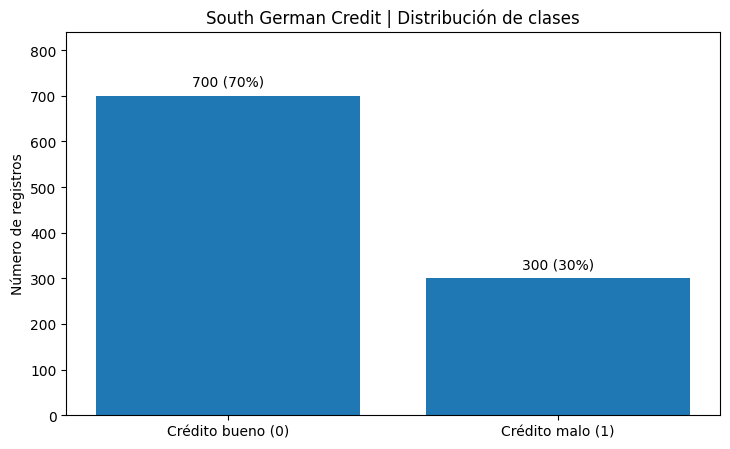

Figura generada: actividad6_resultados/etapa1_distribucion_clases.png


In [5]:
conteos = y.value_counts().reindex([0, 1], fill_value=0)
fig, ax = plt.subplots(figsize=(7.4, 4.6))
barras = ax.bar(['Crédito bueno (0)', 'Crédito malo (1)'], conteos.values)
ax.set_title('South German Credit | Distribución de clases')
ax.set_ylabel('Número de registros')
ax.set_ylim(0, max(conteos.values) * 1.20)
for barra, valor in zip(barras, conteos.values):
    ax.annotate(f'{valor:,} ({valor / len(y):.0%})',
                (barra.get_x() + barra.get_width()/2, barra.get_height()),
                ha='center', va='bottom', xytext=(0, 5), textcoords='offset points')
fig.tight_layout()
fig.savefig(SALIDA / 'etapa1_distribucion_clases.png', dpi=180, bbox_inches='tight')
plt.show()
print('Figura generada:', SALIDA / 'etapa1_distribucion_clases.png')

### 1.6 | Control de la Etapa 1

*Verificación de fuente y recodificacion.*

## ETAPA 2. Modelos y validación cruzada

*Fase: diseño de evaluación y comparación inicial.*

### 2.1 | Criterios de evaluación

*Objetivos SMART y costos ilustrativos.*

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    make_scorer, precision_score, recall_score, f1_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import sklearn

METAS = {'recall': 0.75, 'especificidad': 0.60, 'roc_auc': 0.70}
COSTO_FN_ILUSTRATIVO = 5
COSTO_FP_ILUSTRATIVO = 1

print('Scikit-learn:', sklearn.__version__)
print('Definición del evento: riesgo_alto 1 = crédito malo | 0 = crédito bueno')
print('Metas ex ante:', METAS)
print('Costos ilustrativos FN/FP:', COSTO_FN_ILUSTRATIVO, '/', COSTO_FP_ILUSTRATIVO)
assert y.name == 'riesgo_alto' and y.value_counts().sort_index().to_dict() == {0: 700, 1: 300}
print('VERIFICACIÓN 2.1: objetivo, criterios y codificación confirmados.')

Scikit-learn: 1.6.1
Definición del evento: riesgo_alto 1 = crédito malo | 0 = crédito bueno
Metas ex ante: {'recall': 0.75, 'especificidad': 0.6, 'roc_auc': 0.7}
Costos ilustrativos FN/FP: 5 / 1
VERIFICACIÓN 2.1: objetivo, criterios y codificación confirmados.


### 2.2 | Partición estratificada

*80% desarrollo y 20% prueba independiente.*

In [7]:
indices_desarrollo, indices_prueba = train_test_split(
    X_original.index.to_numpy(),
    test_size=0.20,
    stratify=y.to_numpy(),
    random_state=SEMILLA,
)
X_desarrollo = X_original.loc[indices_desarrollo].copy()
X_prueba = X_original.loc[indices_prueba].copy()
y_desarrollo = y.loc[indices_desarrollo].copy()
y_prueba = y.loc[indices_prueba].copy()

assert len(X_desarrollo) == 800 and len(X_prueba) == 200
assert X_desarrollo.index.intersection(X_prueba.index).empty
assert y_desarrollo.value_counts().sort_index().to_dict() == {0: 560, 1: 240}
assert y_prueba.value_counts().sort_index().to_dict() == {0: 140, 1: 60}
assert X_desarrollo.index.equals(y_desarrollo.index)
assert X_prueba.index.equals(y_prueba.index)

particiones = pd.DataFrame({
    'indice_original': X_original.index,
    'particion': ['desarrollo' if idx in set(indices_desarrollo) else 'prueba'
                  for idx in X_original.index],
})
particiones.to_csv(SALIDA / 'etapa2_particiones.csv', index=False)

print('Desarrollo:', X_desarrollo.shape, '| clases:', y_desarrollo.value_counts().sort_index().to_dict())
print('Prueba:', X_prueba.shape, '| clases:', y_prueba.value_counts().sort_index().to_dict())
print('Índices guardados:', SALIDA / 'etapa2_particiones.csv')
print('VERIFICACIÓN 2.2: partición estratificada independiente confirmada.')

Desarrollo: (800, 20) | clases: {0: 560, 1: 240}
Prueba: (200, 20) | clases: {0: 140, 1: 60}
Índices guardados: actividad6_resultados/etapa2_particiones.csv
VERIFICACIÓN 2.2: partición estratificada independiente confirmada.


### 2.3 | Preparación de variables y modelos

*Pipelines, baseline, regresion logística y Random Forest.*

In [8]:
columnas_numericas = ['duration', 'amount', 'age']
columnas_categoricas = [c for c in X_original.columns if c not in columnas_numericas]
assert len(columnas_numericas) == 3 and len(columnas_categoricas) == 17
assert set(columnas_numericas + columnas_categoricas) == set(X_original.columns)

tratamiento_numerico = Pipeline([
    ('imputacion', SimpleImputer(strategy='median')),
    ('escalado', StandardScaler()),
])
tratamiento_categorico = Pipeline([
    ('imputacion', SimpleImputer(strategy='most_frequent')),
    ('codificacion', OneHotEncoder(handle_unknown='ignore')),
])
preprocesamiento = ColumnTransformer([
    ('numericas', tratamiento_numerico, columnas_numericas),
    ('categoricas', tratamiento_categorico, columnas_categoricas),
], remainder='drop', sparse_threshold=0.0)

estimadores = {
    'Baseline (proporciones)': DummyClassifier(strategy='prior'),
    'Regresión logística': LogisticRegression(max_iter=3000, random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(
        n_estimators=160,
        min_samples_leaf=3,
        random_state=SEMILLA,
        n_jobs=1,
    ),
}
modelos = {
    nombre: Pipeline([
        ('preprocesamiento', preprocesamiento),
        ('clasificador', estimador),
    ])
    for nombre, estimador in estimadores.items()
}

print('Variables numéricas:', columnas_numericas)
print('Variables categóricas/ordinales:', len(columnas_categoricas), columnas_categoricas)
print('Modelos:', ', '.join(modelos))
print('VERIFICACIÓN 2.3: pipelines definidos; todavía no se ha consultado el test.')

Variables numéricas: ['duration', 'amount', 'age']
Variables categóricas/ordinales: 17 ['status', 'credit_history', 'purpose', 'savings', 'employment_duration', 'installment_rate', 'personal_status_sex', 'other_debtors', 'present_residence', 'property', 'other_installment_plans', 'housing', 'number_credits', 'job', 'people_liable', 'telephone', 'foreign_worker']
Modelos: Baseline (proporciones), Regresión logística, Random Forest
VERIFICACIÓN 2.3: pipelines definidos; todavía no se ha consultado el test.


### 2.4 | Validación cruzada

*Cinco folds estratificados sobre desarrollo.*

In [9]:
cv_5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {
    'roc_auc': 'roc_auc',
    'recall': make_scorer(recall_score, pos_label=1, zero_division=0),
    'especificidad': make_scorer(recall_score, pos_label=0, zero_division=0),
    'precision': make_scorer(precision_score, pos_label=1, zero_division=0),
    'f1': make_scorer(f1_score, pos_label=1, zero_division=0),
    'exactitud_balanceada': 'balanced_accuracy',
    'exactitud': 'accuracy',
}

resultados_folds = []
for nombre, modelo in modelos.items():
    evaluacion = cross_validate(
        modelo, X_desarrollo, y_desarrollo,
        scoring=metricas_cv, cv=cv_5,
        n_jobs=1, return_train_score=False,
        error_score='raise',
    )
    for fold in range(5):
        registro = {'modelo': nombre, 'fold': fold + 1}
        for metrica in metricas_cv:
            registro[metrica] = float(evaluacion[f'test_{metrica}'][fold])
        resultados_folds.append(registro)
    print('Validado:', nombre, '| ROC-AUC media:',
          f"{np.mean(evaluacion['test_roc_auc']):.3f}")

df_folds = pd.DataFrame(resultados_folds)
assert len(df_folds) == 15
assert df_folds[sorted(metricas_cv)].notna().all().all(), 'Existen métricas faltantes.'
df_folds.to_csv(SALIDA / 'etapa2_metricas_por_fold.csv', index=False)
print('VERIFICACIÓN 2.4: 15 evaluaciones completadas, sin acceso a test.')

Validado: Baseline (proporciones) | ROC-AUC media: 0.500
Validado: Regresión logística | ROC-AUC media: 0.780
Validado: Random Forest | ROC-AUC media: 0.793
VERIFICACIÓN 2.4: 15 evaluaciones completadas, sin acceso a test.


### 2.5 | Comparación preliminar

*Métricas de CV y gráfica comparativa.*

Comparación preliminar (métricas promedio de validación cruzada):
                 modelo  roc_auc_media  roc_auc_desv  recall_media  especificidad_media  precision_media  f1_media
          Random Forest          0.793         0.042         0.304                0.930            0.656     0.408
    Regresión logística          0.780         0.030         0.488                0.854            0.595     0.533
Baseline (proporciones)          0.500         0.000         0.000                1.000            0.000     0.000


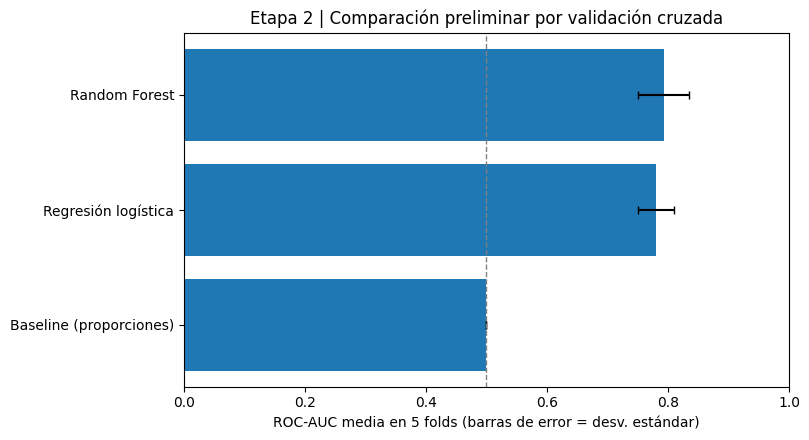

Modelo con mayor ROC-AUC media en desarrollo: Random Forest
Figura: actividad6_resultados/etapa2_comparacion_roc_auc_cv.png
Importante: la selección y el umbral finales permanecen pendientes.
VERIFICACIÓN 2.5: comparación reproducible registrada.


In [10]:
filas_resumen = []
for nombre, bloque in df_folds.groupby('modelo', sort=False):
    fila = {'modelo': nombre}
    for metrica in metricas_cv:
        fila[f'{metrica}_media'] = float(bloque[metrica].mean())
        fila[f'{metrica}_desv'] = float(bloque[metrica].std(ddof=1))
    filas_resumen.append(fila)
resumen_cv = pd.DataFrame(filas_resumen).sort_values(
    'roc_auc_media', ascending=False, kind='stable'
).reset_index(drop=True)
resumen_cv.to_csv(SALIDA / 'etapa2_resumen_validacion_cv.csv', index=False)

columnas_visibles = [
    'modelo', 'roc_auc_media', 'roc_auc_desv', 'recall_media',
    'especificidad_media', 'precision_media', 'f1_media',
]
print('Comparación preliminar (métricas promedio de validación cruzada):')
print(resumen_cv[columnas_visibles].round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(8.2, 4.5))
orden = resumen_cv.sort_values('roc_auc_media', ascending=True)
ax.barh(orden['modelo'], orden['roc_auc_media'], xerr=orden['roc_auc_desv'],
        capsize=3)
ax.set_xlim(0, 1.0)
ax.set_xlabel('ROC-AUC media en 5 folds (barras de error = desv. estándar)')
ax.set_title('Etapa 2 | Comparación preliminar por validación cruzada')
ax.axvline(0.5, color='grey', linestyle='--', linewidth=1)
fig.tight_layout()
fig.savefig(SALIDA / 'etapa2_comparacion_roc_auc_cv.png', dpi=180, bbox_inches='tight')
plt.show()

mejor_modelo_cv = resumen_cv.iloc[0]['modelo']
print('Modelo con mayor ROC-AUC media en desarrollo:', mejor_modelo_cv)
print('Figura:', SALIDA / 'etapa2_comparacion_roc_auc_cv.png')
print('Importante: la selección y el umbral finales permanecen pendientes.')
print('VERIFICACIÓN 2.5: comparación reproducible registrada.')

### 2.6 | Control de la Etapa 2

*Verificación de particiones y resultados.*

## ETAPA 3. Selección del umbral

*Fase: evaluación fuera de fold, sin acceso a prueba.*

### 3.1 | Reglas para seleccionar umbral

*Recall 0.75, especificidad 0.60, AUC 0.70.*

In [11]:
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import cross_val_predict

assert METAS == {'recall': 0.75, 'especificidad': 0.60, 'roc_auc': 0.70}
assert COSTO_FN_ILUSTRATIVO == 5 and COSTO_FP_ILUSTRATIVO == 1
assert len(X_desarrollo) == 800 and len(X_prueba) == 200
assert X_desarrollo.index.intersection(X_prueba.index).empty

CANDIDATOS = ['Regresión logística', 'Random Forest']
CLAVE_MODELO = {'Regresión logística': 'logistica', 'Random Forest': 'forest'}

print('Candidatos:', ', '.join(CANDIDATOS))
print('Metas ya fijadas:', METAS)
print('Regla: mínimo costo ilustrativo ENTRE umbrales factibles; sin cumplimiento no hay aprobación.')
print('VERIFICACIÓN 3.1: regla fijada; conjunto de prueba intacto.')

Candidatos: Regresión logística, Random Forest
Metas ya fijadas: {'recall': 0.75, 'especificidad': 0.6, 'roc_auc': 0.7}
Regla: mínimo costo ilustrativo ENTRE umbrales factibles; sin cumplimiento no hay aprobación.
VERIFICACIÓN 3.1: regla fijada; conjunto de prueba intacto.


### 3.2 | Probabilidades fuera de fold (OOF)

*Predicciones sobre el conjunto de desarrollo.*

In [12]:
probabilidades_oof = {}
df_oof = pd.DataFrame({
    'indice_original': X_desarrollo.index.to_numpy(),
    'riesgo_alto_real': y_desarrollo.to_numpy(),
})

for nombre in CANDIDATOS:
    probs = cross_val_predict(
        modelos[nombre], X_desarrollo, y_desarrollo,
        cv=cv_5, method='predict_proba', n_jobs=1,
    )[:, 1]
    assert probs.shape == (800,)
    assert np.isfinite(probs).all() and np.logical_and(probs >= 0, probs <= 1).all()
    probabilidades_oof[nombre] = probs
    df_oof['proba_' + CLAVE_MODELO[nombre]] = probs
    print(f'{nombre} | ROC-AUC OOF agrupada: {roc_auc_score(y_desarrollo, probs):.3f}')

assert len(df_oof) == 800 and df_oof['indice_original'].is_unique
assert int(df_oof['riesgo_alto_real'].sum()) == 240
archivo_oof = SALIDA / 'etapa3_probabilidades_oof_desarrollo.csv'
df_oof.to_csv(archivo_oof, index=False)
print('Predicciones guardadas:', archivo_oof)
print('Nota: AUC OOF agrupada y media de AUC de cinco folds no tienen por qué coincidir exactamente.')
print('VERIFICACIÓN 3.2: predicciones OOF completas, sin uso de prueba.')

Regresión logística | ROC-AUC OOF agrupada: 0.779
Random Forest | ROC-AUC OOF agrupada: 0.792
Predicciones guardadas: actividad6_resultados/etapa3_probabilidades_oof_desarrollo.csv
Nota: AUC OOF agrupada y media de AUC de cinco folds no tienen por qué coincidir exactamente.
VERIFICACIÓN 3.2: predicciones OOF completas, sin uso de prueba.


### 3.3 | Barrido de umbrales

*Métricas y costos ilustrativos por umbral.*

In [13]:
def evaluar_umbral(y_real, probabilidades, umbral):
    pred = (np.asarray(probabilidades) >= umbral).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_real, pred, labels=[0, 1]).ravel()
    sensibilidad = tp / (tp + fn) if (tp + fn) else 0.0
    especificidad = tn / (tn + fp) if (tn + fp) else 0.0
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    f1 = (2 * precision * sensibilidad / (precision + sensibilidad)
          if (precision + sensibilidad) else 0.0)
    return {
        'umbral': float(umbral), 'TN': int(tn), 'FP': int(fp),
        'FN': int(fn), 'TP': int(tp),
        'recall': float(sensibilidad), 'especificidad': float(especificidad),
        'precision': float(precision), 'f1': float(f1),
        'exactitud': float((tp + tn) / len(pred)),
        'costo_ponderado': int(COSTO_FN_ILUSTRATIVO * fn + COSTO_FP_ILUSTRATIVO * fp),
        'tasa_alertas': float(np.mean(pred)),
    }

UMBRALES = np.round(np.arange(0.01, 1.00, 0.01), 2)
filas_umbral = []
for nombre in CANDIDATOS:
    auc_oof = float(roc_auc_score(y_desarrollo, probabilidades_oof[nombre]))
    for umbral in UMBRALES:
        fila = evaluar_umbral(y_desarrollo, probabilidades_oof[nombre], float(umbral))
        fila.update({'modelo': nombre, 'roc_auc_oof': auc_oof})
        fila['cumple_recall'] = fila['recall'] >= METAS['recall']
        fila['cumple_especificidad'] = fila['especificidad'] >= METAS['especificidad']
        fila['cumple_objetivos'] = (
            fila['cumple_recall'] and fila['cumple_especificidad']
            and auc_oof >= METAS['roc_auc']
        )
        filas_umbral.append(fila)

df_umbrales = pd.DataFrame(filas_umbral)
assert len(df_umbrales) == 198
assert df_umbrales.groupby('modelo').size().eq(99).all()
df_umbrales.to_csv(SALIDA / 'etapa3_barrido_umbrales.csv', index=False)
print('Referencia a umbral 0.50 (OOF, una observación fuera de su fold):')
print(df_umbrales[np.isclose(df_umbrales['umbral'], 0.50)][
    ['modelo', 'umbral', 'TN', 'FP', 'FN', 'TP', 'recall',
     'especificidad', 'f1', 'costo_ponderado']
].round(3).to_string(index=False))
print('VERIFICACIÓN 3.3: 198 combinaciones modelo-umbral calculadas.')

Referencia a umbral 0.50 (OOF, una observación fuera de su fold):
             modelo  umbral  TN  FP  FN  TP  recall  especificidad    f1  costo_ponderado
Regresión logística     0.5 478  82 123 117   0.488          0.854 0.533              697
      Random Forest     0.5 521  39 167  73   0.304          0.930 0.415              874
VERIFICACIÓN 3.3: 198 combinaciones modelo-umbral calculadas.


### 3.4 | Selección provisional

*Modelo y umbral candidatos.*

In [14]:
def elegir_fila_modelo(tabla):
    t = tabla.copy()
    # Distancia absoluta a metas incumplidas, escala 0 a 1 para cada métrica.
    t['brecha_recall'] = np.maximum(0, METAS['recall'] - t['recall'])
    t['brecha_especificidad'] = np.maximum(0, METAS['especificidad'] - t['especificidad'])
    t['brecha_total'] = t['brecha_recall'] + t['brecha_especificidad']
    factibles = t[t['cumple_recall'] & t['cumple_especificidad']]
    if len(factibles):
        eleccion = factibles.sort_values(
            ['costo_ponderado', 'FN', 'FP', 'umbral'],
            ascending=[True, True, True, False], kind='stable'
        ).iloc[0].copy()
        eleccion['criterio'] = 'Mínimo costo entre umbrales factibles'
    else:
        eleccion = t.sort_values(
            ['brecha_total', 'costo_ponderado', 'FN'],
            ascending=[True, True, True], kind='stable'
        ).iloc[0].copy()
        eleccion['criterio'] = 'Exploratorio: no existe umbral factible'
    return eleccion

selecciones = []
for nombre in CANDIDATOS:
    seleccion = elegir_fila_modelo(df_umbrales[df_umbrales['modelo'] == nombre])
    selecciones.append(seleccion)

df_seleccion = pd.DataFrame(selecciones).reset_index(drop=True)
df_seleccion['brecha_roc_auc'] = np.maximum(0, METAS['roc_auc'] - df_seleccion['roc_auc_oof'])
df_seleccion['brecha_total_modelo'] = df_seleccion['brecha_total'] + df_seleccion['brecha_roc_auc']
validos = df_seleccion[df_seleccion['cumple_objetivos']]
if len(validos):
    ganador = validos.sort_values(
        ['costo_ponderado', 'FN', 'roc_auc_oof'],
        ascending=[True, True, False], kind='stable'
    ).iloc[0]
    estado_preliminar = 'Candidato que cumple metas OOF; requiere evaluación independiente'
else:
    ganador = df_seleccion.sort_values(
        ['brecha_total_modelo', 'costo_ponderado', 'roc_auc_oof'],
        ascending=[True, True, False], kind='stable'
    ).iloc[0]
    estado_preliminar = 'NINGÚN CANDIDATO CUMPLE TODAS LAS METAS; ejemplo exploratorio'

modelo_provisional = str(ganador['modelo'])
umbral_provisional = float(ganador['umbral'])
df_seleccion.to_csv(SALIDA / 'etapa3_seleccion_provisional.csv', index=False)
print('Resumen de umbral seleccionado por candidato:')
print(df_seleccion[[
    'modelo', 'umbral', 'roc_auc_oof', 'recall', 'especificidad',
    'precision', 'f1', 'FN', 'FP', 'costo_ponderado', 'cumple_objetivos', 'criterio'
]].round(3).to_string(index=False))
print('\nEstado:', estado_preliminar)
print('Referencia exploratoria:', modelo_provisional, '| umbral:', f'{umbral_provisional:.2f}')
print('Costo ilustrativo baseline que siempre predice bueno:', 5 * int(y_desarrollo.sum()))
print('ADVERTENCIA: la selección del umbral usa los OOF; las métricas seleccionadas pueden ser optimistas.')
print('VERIFICACIÓN 3.4: umbrales seleccionados sin consultar el test.')

Resumen de umbral seleccionado por candidato:
             modelo  umbral  roc_auc_oof  recall  especificidad  precision    f1  FN  FP  costo_ponderado  cumple_objetivos                              criterio
Regresión logística    0.21        0.779   0.792          0.607      0.463 0.585  50 220              470              True Mínimo costo entre umbrales factibles
      Random Forest    0.28        0.792   0.817          0.618      0.478 0.603  44 214              434              True Mínimo costo entre umbrales factibles

Estado: Candidato que cumple metas OOF; requiere evaluación independiente
Referencia exploratoria: Random Forest | umbral: 0.28
Costo ilustrativo baseline que siempre predice bueno: 1200
ADVERTENCIA: la selección del umbral usa los OOF; las métricas seleccionadas pueden ser optimistas.
VERIFICACIÓN 3.4: umbrales seleccionados sin consultar el test.


### 3.5 | Curvas ROC y compromiso de errores

*Sensibilidad y especificidad frente al umbral.*

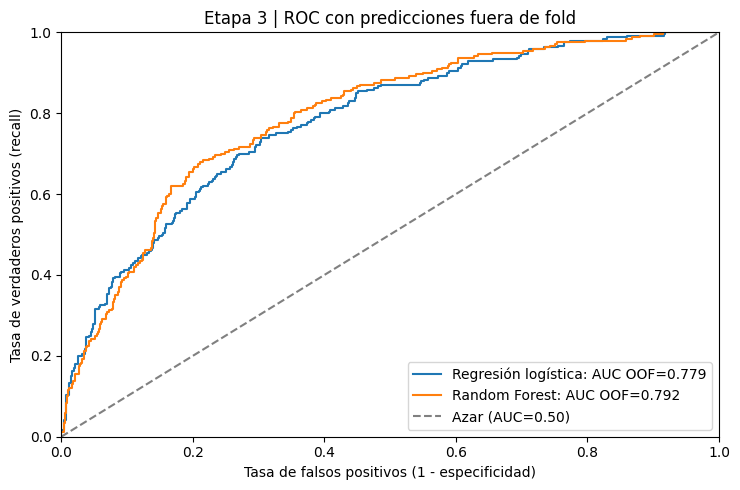

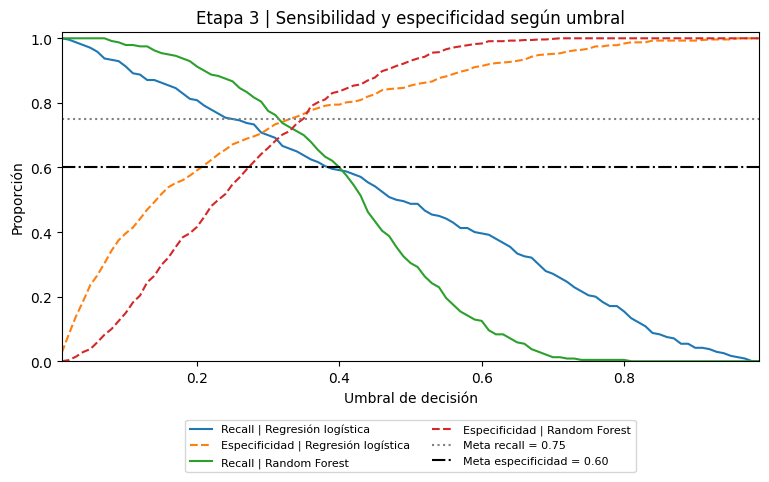

Figuras ROC y compromiso de umbrales guardadas.


In [15]:
fig, ax = plt.subplots(figsize=(7.5, 5.0))
for nombre in CANDIDATOS:
    fpr, tpr, _ = roc_curve(y_desarrollo, probabilidades_oof[nombre])
    auc_oof = roc_auc_score(y_desarrollo, probabilidades_oof[nombre])
    ax.plot(fpr, tpr, label=f'{nombre}: AUC OOF={auc_oof:.3f}')
ax.plot([0, 1], [0, 1], linestyle='--', color='grey', label='Azar (AUC=0.50)')
ax.set(xlim=(0, 1), ylim=(0, 1), xlabel='Tasa de falsos positivos (1 - especificidad)',
       ylabel='Tasa de verdaderos positivos (recall)', title='Etapa 3 | ROC con predicciones fuera de fold')
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(SALIDA / 'etapa3_curva_roc_oof.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9.0, 5.4))
for nombre in CANDIDATOS:
    datos = df_umbrales[df_umbrales['modelo'] == nombre]
    ax.plot(datos['umbral'], datos['recall'], label=f'Recall | {nombre}')
    ax.plot(datos['umbral'], datos['especificidad'], linestyle='--',
            label=f'Especificidad | {nombre}')
ax.axhline(METAS['recall'], linestyle=':', color='grey', label='Meta recall = 0.75')
ax.axhline(METAS['especificidad'], linestyle='-.', color='black', label='Meta especificidad = 0.60')
ax.set(xlim=(0.01, .99), ylim=(0, 1.02), xlabel='Umbral de decisión',
       ylabel='Proporción', title='Etapa 3 | Sensibilidad y especificidad según umbral')
ax.legend(fontsize=8, ncol=2, loc='upper center', bbox_to_anchor=(0.5, -0.16))
fig.subplots_adjust(bottom=0.27)
fig.savefig(SALIDA / 'etapa3_recall_especificidad_por_umbral.png', dpi=180, bbox_inches='tight')
plt.show()
print('Figuras ROC y compromiso de umbrales guardadas.')

### 3.6 | Matrices de confusión

*Umbral predeterminado y umbral seleccionado.*

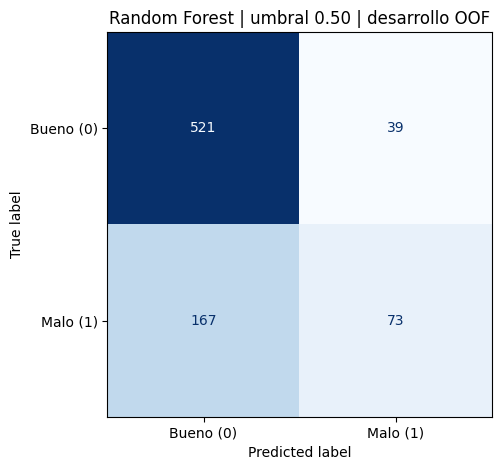

Guardada: actividad6_resultados/etapa3_matriz_predeterminado_050.png


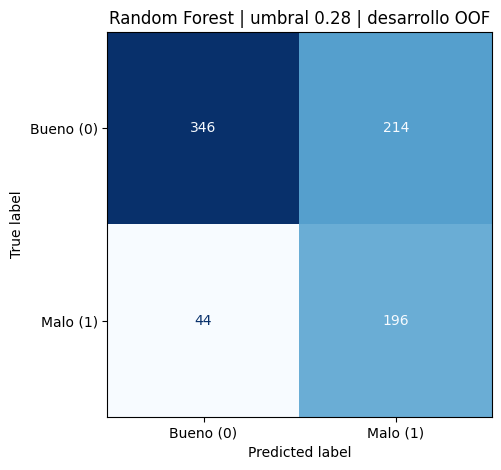

Guardada: actividad6_resultados/etapa3_matriz_seleccionado.png
Registro: actividad6_resultados/etapa3_registro_experimento.json
VERIFICACIÓN 3.6: visualizaciones y registro reproducible generados.


In [16]:
from sklearn.metrics import ConfusionMatrixDisplay
from datetime import datetime, timezone

for nombre_umbral, umbral in [('predeterminado_050', 0.50), ('seleccionado', umbral_provisional)]:
    y_pred = (probabilidades_oof[modelo_provisional] >= umbral).astype(int)
    cm = confusion_matrix(y_desarrollo, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(5.8, 4.8))
    ConfusionMatrixDisplay(
        confusion_matrix=cm, display_labels=['Bueno (0)', 'Malo (1)']
    ).plot(ax=ax, colorbar=False, cmap='Blues', values_format='d')
    ax.set_title(f'{modelo_provisional} | umbral {umbral:.2f} | desarrollo OOF')
    fig.tight_layout()
    nombre_archivo = SALIDA / f'etapa3_matriz_{nombre_umbral}.png'
    fig.savefig(nombre_archivo, dpi=180, bbox_inches='tight')
    plt.show()
    print('Guardada:', nombre_archivo)

registro = {
    'generado_utc': datetime.now(timezone.utc).isoformat(),
    'fuente': 'South German Credit, UCI (dataset 573)',
    'etapa': '3 - ajuste de umbral',
    'semilla': SEMILLA,
    'n_desarrollo': len(X_desarrollo),
    'folds': 5,
    'evento_positivo': 'riesgo_alto=1, crédito malo',
    'metas': METAS,
    'costo_FN_FP_ilustrativo': [COSTO_FN_ILUSTRATIVO, COSTO_FP_ILUSTRATIVO],
    'barrido_umbrales': {'inicio': 0.01, 'fin': 0.99, 'paso': 0.01},
    'modelos_comparados': CANDIDATOS,
    'modelo_provisional': modelo_provisional,
    'umbral_provisional': umbral_provisional,
    'estado': estado_preliminar,
    'advertencias': [
        'Métricas de selección del umbral estimadas sobre desarrollo OOF: pueden ser optimistas.',
        'No se han utilizado ni evaluado los 200 registros de prueba.',
        'Costos relativos 5 a 1 ilustrativos, sin validación económica en cartera real.',
        'No es una recomendación de despliegue ni de decisiones crediticias automatizadas.',
    ],
}
(SALIDA / 'etapa3_registro_experimento.json').write_text(
    json.dumps(registro, indent=2, ensure_ascii=False), encoding='utf-8'
)
assert (SALIDA / 'etapa3_seleccion_provisional.csv').exists()
assert (SALIDA / 'etapa3_registro_experimento.json').exists()
print('Registro:', SALIDA / 'etapa3_registro_experimento.json')
print('VERIFICACIÓN 3.6: visualizaciones y registro reproducible generados.')

### 3.7 | Control de la Etapa 3

*Revision de métricas y registro de experimento.*

## ETAPA 4. Validación estadística y A/B simulado

*Fase: contrastes e incertidumbre sobre desarrollo.*

### 4.1 | Congelación de candidatos

*Parametros y umbrales definidos previamente.*

In [17]:
# Los dos umbrales provienen de la Etapa 3: no se reoptimizan en esta etapa.
UMBRAL_POR_MODELO = {
    nombre: float(df_seleccion.set_index('modelo').loc[nombre, 'umbral'])
    for nombre in CANDIDATOS
}
assert set(UMBRAL_POR_MODELO) == set(CANDIDATOS)
assert len(y_desarrollo) == 800 and len(y_prueba) == 200
assert not X_desarrollo.index.intersection(X_prueba.index).any()
assert np.array_equal(y_desarrollo.to_numpy(), df_oof['riesgo_alto_real'].to_numpy())
assert set(df_oof['indice_original']) == set(X_desarrollo.index)

print('Umbrales previamente fijados:', UMBRAL_POR_MODELO)
print('Modelo candidato de Etapa 3:', modelo_provisional, '| umbral:', umbral_provisional)
print('Conjunto usado: desarrollo OOF, 800 registros; test reservado: 200 registros.')
print('VERIFICACIÓN 4.1: parámetros congelados; test no consultado.')


Umbrales previamente fijados: {'Regresión logística': 0.21, 'Random Forest': 0.28}
Modelo candidato de Etapa 3: Random Forest | umbral: 0.28
Conjunto usado: desarrollo OOF, 800 registros; test reservado: 200 registros.
VERIFICACIÓN 4.1: parámetros congelados; test no consultado.


### 4.2 | Comparación estadística de ROC-AUC

*Intervalo bootstrap pareado del 95%.*

In [18]:
# Remuestreo pareado y estratificado: no se recalculan modelos ni se toca el conjunto de prueba.
N_BOOT = 2000
rng_boot = np.random.default_rng(SEMILLA + 404)
y_dev_np = y_desarrollo.to_numpy(dtype=int)
pos = np.flatnonzero(y_dev_np == 1)
neg = np.flatnonzero(y_dev_np == 0)
p_lr = np.asarray(probabilidades_oof['Regresión logística'], dtype=float)
p_rf = np.asarray(probabilidades_oof['Random Forest'], dtype=float)
auc_lr = float(roc_auc_score(y_dev_np, p_lr))
auc_rf = float(roc_auc_score(y_dev_np, p_rf))
dif_auc = auc_rf - auc_lr
muestras_auc = np.empty(N_BOOT, dtype=float)
for i in range(N_BOOT):
    ids = np.concatenate([
        rng_boot.choice(neg, size=len(neg), replace=True),
        rng_boot.choice(pos, size=len(pos), replace=True),
    ])
    muestras_auc[i] = roc_auc_score(y_dev_np[ids], p_rf[ids]) - roc_auc_score(y_dev_np[ids], p_lr[ids])
ci_auc = np.quantile(muestras_auc, [0.025, 0.975])

print(f'ROC-AUC OOF logística: {auc_lr:.3f} | Random Forest: {auc_rf:.3f}')
print(f'Diferencia (RF - logística): {dif_auc:+.3f}')
print(f'IC bootstrap pareado 95% (exploratorio): [{ci_auc[0]:+.3f}, {ci_auc[1]:+.3f}]')
print('¿Incluye cero el IC?:', bool(ci_auc[0] <= 0 <= ci_auc[1]))
print('Limitación: bootstrap sobre predicciones OOF previamente seleccionadas, no prueba confirmatoria.')
print('VERIFICACIÓN 4.2: comparación de AUC y estimación de incertidumbre generadas.')


ROC-AUC OOF logística: 0.779 | Random Forest: 0.792
Diferencia (RF - logística): +0.013
IC bootstrap pareado 95% (exploratorio): [-0.007, +0.032]
¿Incluye cero el IC?: True
Limitación: bootstrap sobre predicciones OOF previamente seleccionadas, no prueba confirmatoria.
VERIFICACIÓN 4.2: comparación de AUC y estimación de incertidumbre generadas.


### 4.3 | Comparación de costos ilustrativos

*Diferencias pareadas y su incertidumbre.*

In [19]:
def costo_por_registro(y_real, proba, umbral):
    pred = (np.asarray(proba) >= float(umbral)).astype(int)
    y_real = np.asarray(y_real, dtype=int)
    return np.where((y_real == 1) & (pred == 0), COSTO_FN_ILUSTRATIVO,
                    np.where((y_real == 0) & (pred == 1), COSTO_FP_ILUSTRATIVO, 0)).astype(float)

costos_lr = costo_por_registro(y_dev_np, p_lr, UMBRAL_POR_MODELO['Regresión logística'])
costos_rf = costo_por_registro(y_dev_np, p_rf, UMBRAL_POR_MODELO['Random Forest'])
dif_costos_pareada = costos_rf - costos_lr
media_dif_pareada = float(np.mean(dif_costos_pareada))
rng_pareado = np.random.default_rng(SEMILLA + 405)
bootstrap_dif = np.empty(N_BOOT)
for i in range(N_BOOT):
    ids = rng_pareado.integers(0, len(dif_costos_pareada), len(dif_costos_pareada))
    bootstrap_dif[i] = dif_costos_pareada[ids].mean()
ci_pareado = np.quantile(bootstrap_dif, [.025, .975])

print('Total costos OOF logística:', int(costos_lr.sum()))
print('Total costos OOF Random Forest:', int(costos_rf.sum()))
print('Diferencia media por registro (RF - logística):', round(media_dif_pareada, 4))
print(f'IC bootstrap pareado 95%: [{ci_pareado[0]:+.4f}, {ci_pareado[1]:+.4f}]')
print('Casos RF menor costo / mayor costo / empate:',
      int((dif_costos_pareada < 0).sum()), int((dif_costos_pareada > 0).sum()),
      int((dif_costos_pareada == 0).sum()))
print('Interpretación: una diferencia negativa favorece RF bajo el supuesto ilustrativo 5:1.')
print('VERIFICACIÓN 4.3: comparación pareada exploratoria completada.')


Total costos OOF logística: 470
Total costos OOF Random Forest: 434
Diferencia media por registro (RF - logística): -0.045
IC bootstrap pareado 95%: [-0.1150, +0.0250]
Casos RF menor costo / mayor costo / empate: 70 58 672
Interpretación: una diferencia negativa favorece RF bajo el supuesto ilustrativo 5:1.
VERIFICACIÓN 4.3: comparación pareada exploratoria completada.


### 4.4 | Simulación A/B

*Asignacion aleatoria y contraste exploratorio.*

In [20]:
N_PERM = 5000
semilla_ab = SEMILLA + 406
rng_ab = np.random.default_rng(semilla_ab)
# Permutación fija 1:1. Asignación sin usar las etiquetas reales.
permutacion = rng_ab.permutation(len(y_dev_np))
asignacion = np.full(len(y_dev_np), 'A', dtype='<U1')
asignacion[permutacion[len(y_dev_np)//2:]] = 'B'
assert np.sum(asignacion == 'A') == np.sum(asignacion == 'B') == 400

# Únicamente el resultado de la política asignada entra al análisis A/B.
costo_observado = np.where(asignacion == 'A', costos_lr, costos_rf)
valores_a = costo_observado[asignacion == 'A']
valores_b = costo_observado[asignacion == 'B']
delta_ab = float(valores_b.mean() - valores_a.mean())

# Prueba de randomización bajo hipótesis nula de efecto nulo, diferencia absoluta de medias.
rng_perm = np.random.default_rng(SEMILLA + 407)
deltas_nulos = np.empty(N_PERM)
for i in range(N_PERM):
    ids_perm = rng_perm.permutation(len(costo_observado))
    deltas_nulos[i] = costo_observado[ids_perm[400:]].mean() - costo_observado[ids_perm[:400]].mean()
p_ab = float((1 + np.sum(np.abs(deltas_nulos) >= abs(delta_ab))) / (N_PERM + 1))

# IC bootstrap no pareado: se remuestrea separadamente dentro de cada brazo.
rng_ic_ab = np.random.default_rng(SEMILLA + 408)
boot_ab = np.empty(N_BOOT)
for i in range(N_BOOT):
    boot_ab[i] = (rng_ic_ab.choice(valores_b, size=400, replace=True).mean()
                  - rng_ic_ab.choice(valores_a, size=400, replace=True).mean())
ci_ab = np.quantile(boot_ab, [.025, .975])

simulacion_ab = pd.DataFrame({
    'indice_original': X_desarrollo.index.to_numpy(),
    'grupo_asignado': asignacion,
    'riesgo_alto_real': y_dev_np,
    'costo_observado_politica_asignada': costo_observado.astype(int),
})
simulacion_ab.to_csv(SALIDA / 'etapa4_simulacion_ab_asignaciones.csv', index=False)

print('A/B SIMULADO | n por grupo: A=400 | B=400 | semilla:', semilla_ab)
print('Prevalencia clase positiva (solo para auditoría de balance):',
      {g: round(float(y_dev_np[asignacion == g].mean()), 3) for g in ['A','B']})
print(f'Costo medio A (logística): {valores_a.mean():.4f} | B (RF): {valores_b.mean():.4f}')
print(f'Diferencia B - A: {delta_ab:+.4f} unidades por caso')
print(f'IC bootstrap 95%: [{ci_ab[0]:+.4f}, {ci_ab[1]:+.4f}]')
print(f'p de permutaciones bilateral: {p_ab:.4f} | umbral exploratorio α=0.05')
print('¿Se rechaza H0 al 5%?:', 'Sí, exploratoriamente' if p_ab < .05 else 'No')
print('IMPORTANTE: simulación retrospectiva; no demuestra beneficio causal ni financiero.')
print('VERIFICACIÓN 4.4: asignación A/B y contraste exploratorio reproducibles.')


A/B SIMULADO | n por grupo: A=400 | B=400 | semilla: 448
Prevalencia clase positiva (solo para auditoría de balance): {'A': 0.318, 'B': 0.282}
Costo medio A (logística): 0.5675 | B (RF): 0.5250
Diferencia B - A: -0.0425 unidades por caso
IC bootstrap 95%: [-0.2000, +0.1251]
p de permutaciones bilateral: 0.6395 | umbral exploratorio α=0.05
¿Se rechaza H0 al 5%?: No
IMPORTANTE: simulación retrospectiva; no demuestra beneficio causal ni financiero.
VERIFICACIÓN 4.4: asignación A/B y contraste exploratorio reproducibles.


### 4.5 | Resumen estadistico y visualizaciones

*Resultados e intervalos de confianza.*

                       analisis  efecto_B_menos_A  IC95_inferior  IC95_superior  valor_p                     escala
          ROC-AUC pareado (OOF)            0.0129        -0.0074         0.0320      NaN                 puntos AUC
      Costo medio pareado (OOF)           -0.0450        -0.1150         0.0250      NaN unidades ilustrativas/caso
A/B simulado (aleatorizado 1:1)           -0.0425        -0.2000         0.1251   0.6395 unidades ilustrativas/caso


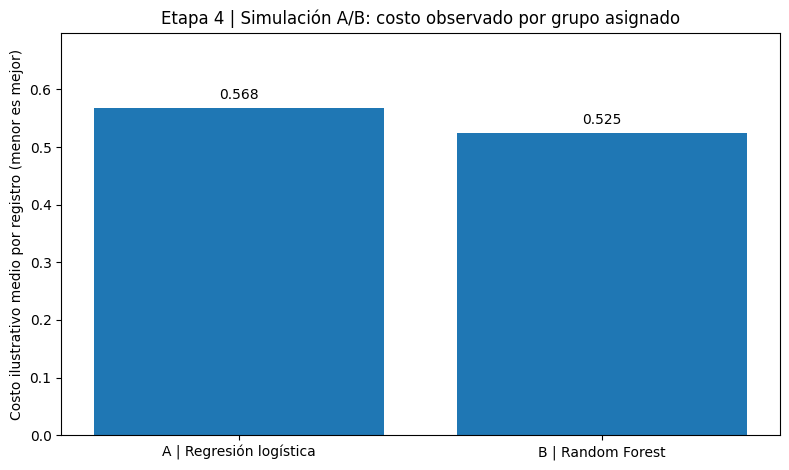

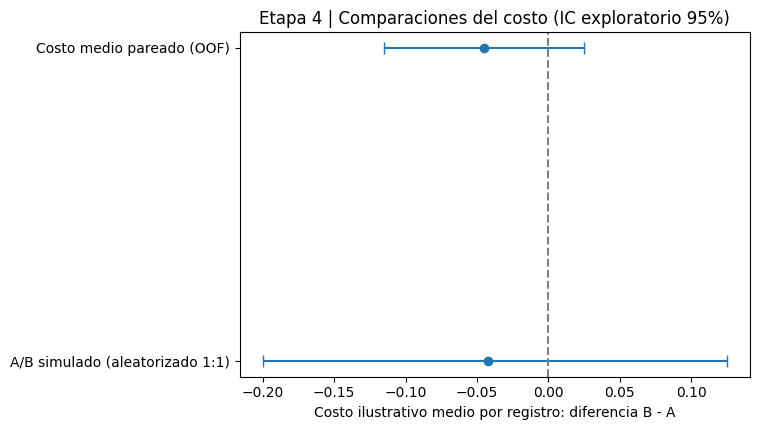

VERIFICACIÓN 4.5: tabla de incertidumbre y gráficos exportados.


In [21]:
tabla_estadistica = pd.DataFrame([
    {'analisis':'ROC-AUC pareado (OOF)', 'efecto_B_menos_A':dif_auc,
     'IC95_inferior':ci_auc[0], 'IC95_superior':ci_auc[1], 'valor_p':np.nan,
     'escala':'puntos AUC'},
    {'analisis':'Costo medio pareado (OOF)', 'efecto_B_menos_A':media_dif_pareada,
     'IC95_inferior':ci_pareado[0], 'IC95_superior':ci_pareado[1], 'valor_p':np.nan,
     'escala':'unidades ilustrativas/caso'},
    {'analisis':'A/B simulado (aleatorizado 1:1)', 'efecto_B_menos_A':delta_ab,
     'IC95_inferior':ci_ab[0], 'IC95_superior':ci_ab[1], 'valor_p':p_ab,
     'escala':'unidades ilustrativas/caso'},
])
tabla_estadistica.to_csv(SALIDA / 'etapa4_resumen_estadistico.csv', index=False)
print(tabla_estadistica.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(8,4.8))
labels = ['A | Regresión logística', 'B | Random Forest']
medias = [float(valores_a.mean()), float(valores_b.mean())]
ax.bar(labels, medias)
for i, media in enumerate(medias):
    ax.text(i, media + .015, f'{media:.3f}', ha='center')
ax.set_ylabel('Costo ilustrativo medio por registro (menor es mejor)')
ax.set_ylim(0, max(medias) * 1.23 if max(medias)>0 else 1)
ax.set_title('Etapa 4 | Simulación A/B: costo observado por grupo asignado')
fig.tight_layout()
fig.savefig(SALIDA / 'etapa4_ab_costos_medios.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7.7,4.4))
# Sólo medidas en la misma unidad: diferencia de costo por registro.
tabla_costos = tabla_estadistica.iloc[[1, 2]].reset_index(drop=True)
indices_ci = np.arange(len(tabla_costos))
y_centro = tabla_costos['efecto_B_menos_A'].to_numpy()
lim_inf = tabla_costos['IC95_inferior'].to_numpy()
lim_sup = tabla_costos['IC95_superior'].to_numpy()
ax.errorbar(y_centro, indices_ci, xerr=[y_centro-lim_inf,lim_sup-y_centro],
            fmt='o', capsize=4)
ax.axvline(0, linestyle='--', color='grey')
ax.set_yticks(indices_ci, tabla_costos['analisis'].tolist())
ax.set_xlabel('Costo ilustrativo medio por registro: diferencia B - A')
ax.set_title('Etapa 4 | Comparaciones del costo (IC exploratorio 95%)')
ax.invert_yaxis()
fig.tight_layout()
fig.savefig(SALIDA / 'etapa4_intervalos_exploratorios.png', dpi=180, bbox_inches='tight')
plt.show()
print('VERIFICACIÓN 4.5: tabla de incertidumbre y gráficos exportados.')


### 4.6 | Registro de la Etapa 4

*Parametros, resultados y trazabilidad.*

In [22]:
registro_4 = {
    'etapa': 4,
    'nombre': 'Contraste estadístico exploratorio y simulación A/B',
    'semilla_base': SEMILLA, 'semilla_ab': semilla_ab,
    'n_desarrollo': int(len(X_desarrollo)), 'n_test_reservado_sin_evaluar': int(len(X_prueba)),
    'n_bootstrap': N_BOOT, 'n_permutaciones_ab': N_PERM,
    'umbral_candidato_A': UMBRAL_POR_MODELO['Regresión logística'],
    'umbral_candidato_B': UMBRAL_POR_MODELO['Random Forest'],
    'modelo_provisional_para_test': modelo_provisional,
    'umbral_provisional_para_test': umbral_provisional,
    'costo_fn': COSTO_FN_ILUSTRATIVO, 'costo_fp': COSTO_FP_ILUSTRATIVO,
    'auc_b_menos_a': float(dif_auc), 'ic95_auc': [float(z) for z in ci_auc],
    'costo_pareado_b_menos_a': float(media_dif_pareada),
    'ic95_costo_pareado': [float(z) for z in ci_pareado],
    'ab_simulado': {
        'grupo_A': 400, 'grupo_B': 400,
        'costo_medio_A': float(valores_a.mean()), 'costo_medio_B': float(valores_b.mean()),
        'diferencia_B_menos_A': float(delta_ab),
        'ic95_bootstrap': [float(z) for z in ci_ab],
        'p_permutaciones_bilateral': float(p_ab), 'alpha_exploratorio': .05,
    },
    'limitaciones': [
        'Seleccion de modelos y umbrales sobre los mismos OOF: inferencia exploratoria y optimismo posible.',
        'Bootstrap OOF no captura el reentrenamiento ni valida generalizacion externa.',
        'A/B simulado sobre datos historicos: no existe tratamiento real ni efecto causal observado.',
        'Costos 5:1 hipoteticos: no son perdidas monetarias ni tasas representativas de cartera.',
        'Test independiente reservado para etapa posterior.',
    ],
}
(SALIDA / 'etapa4_registro_estadistico_y_ab.json').write_text(
    json.dumps(registro_4, indent=2, ensure_ascii=False), encoding='utf-8')
archivos_4 = ['etapa4_simulacion_ab_asignaciones.csv', 'etapa4_resumen_estadistico.csv',
              'etapa4_ab_costos_medios.png', 'etapa4_intervalos_exploratorios.png',
              'etapa4_registro_estadistico_y_ab.json']
assert all((SALIDA / a).exists() for a in archivos_4)
assert modelo_provisional in CANDIDATOS
assert 0 < umbral_provisional < 1
print('Artefactos generados:', ', '.join(archivos_4))
print('Test independiente permanece sin utilizar. Ninguna decisión de despliegue está aprobada.')
print('VERIFICACIÓN 4.6: registro, evidencias y control de integridad completados.')


Artefactos generados: etapa4_simulacion_ab_asignaciones.csv, etapa4_resumen_estadistico.csv, etapa4_ab_costos_medios.png, etapa4_intervalos_exploratorios.png, etapa4_registro_estadistico_y_ab.json
Test independiente permanece sin utilizar. Ninguna decisión de despliegue está aprobada.
VERIFICACIÓN 4.6: registro, evidencias y control de integridad completados.


### 4.7 | Control de la Etapa 4

*Revision del contraste y las limitaciones.*

## ETAPA 5. Evaluación independiente

*Fase: prueba final con modelo y umbral congelados.*

### 5.1 | Protocolo final congelado

*Random Forest; umbral 0.28.*

In [23]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix, ConfusionMatrixDisplay

MODELO_FINAL_FIJADO = 'Random Forest'
UMBRAL_FINAL_FIJADO = 0.28
UMBRAL_LOGISTICA_FIJADO = 0.21
N_BOOT_TEST = 2000

assert modelo_provisional == MODELO_FINAL_FIJADO, 'Cambio de candidato: detener y revisar.'
assert np.isclose(umbral_provisional, UMBRAL_FINAL_FIJADO), 'Umbral distinto al registrado.'
assert np.isclose(UMBRAL_POR_MODELO['Regresión logística'], UMBRAL_LOGISTICA_FIJADO)
assert np.isclose(UMBRAL_POR_MODELO[MODELO_FINAL_FIJADO], UMBRAL_FINAL_FIJADO)
assert len(X_desarrollo) == 800 and len(X_prueba) == 200
assert X_desarrollo.index.intersection(X_prueba.index).empty
assert y_prueba.value_counts().sort_index().to_dict() == {0: 140, 1: 60}
assert METAS == {'recall': 0.75, 'especificidad': 0.60, 'roc_auc': 0.70}

print('Modelo previamente seleccionado:', MODELO_FINAL_FIJADO)
print('Umbral congelado:', UMBRAL_FINAL_FIJADO)
print('Metas fijadas antes del test:', METAS)
print('Desarrollo:', len(X_desarrollo), '| prueba independiente:', len(X_prueba))
print('VERIFICACION 5.1: reglas congeladas antes de la primera evaluacion del test.')

Modelo previamente seleccionado: Random Forest
Umbral congelado: 0.28
Metas fijadas antes del test: {'recall': 0.75, 'especificidad': 0.6, 'roc_auc': 0.7}
Desarrollo: 800 | prueba independiente: 200
VERIFICACION 5.1: reglas congeladas antes de la primera evaluacion del test.


### 5.2 | Predicciones sobre prueba reservada

*Entrenamiento en desarrollo y evaluación independiente.*

In [24]:
modelos_test_fijos = ['Baseline (proporciones)', 'Regresión logística', MODELO_FINAL_FIJADO]
umbrales_test_fijos = {
    'Baseline (proporciones)': 0.50,
    'Regresión logística': UMBRAL_LOGISTICA_FIJADO,
    MODELO_FINAL_FIJADO: UMBRAL_FINAL_FIJADO,
}
probas_test = {}
pred_test = {}
modelos_entrenados = {}

for nombre in modelos_test_fijos:
    ajustado = clone(modelos[nombre])
    ajustado.fit(X_desarrollo, y_desarrollo)
    proba = ajustado.predict_proba(X_prueba)[:, 1]
    pred = (proba >= umbrales_test_fijos[nombre]).astype(int)
    assert len(proba) == len(y_prueba) == 200
    assert np.isfinite(proba).all() and np.all((proba >= 0) & (proba <= 1))
    modelos_entrenados[nombre] = ajustado
    probas_test[nombre] = proba
    pred_test[nombre] = pred
    print(nombre, '| umbral:', f'{umbrales_test_fijos[nombre]:.2f}',
          '| predicciones positivas:', int(pred.sum()))

predicciones_prueba = pd.DataFrame({
    'indice_original': X_prueba.index.to_numpy(),
    'riesgo_alto_real': y_prueba.to_numpy(dtype=int),
})
for nombre in modelos_test_fijos:
    clave = {'Baseline (proporciones)': 'baseline',
             'Regresión logística': 'logistica',
             'Random Forest': 'forest'}[nombre]
    predicciones_prueba[f'probabilidad_{clave}'] = probas_test[nombre]
    predicciones_prueba[f'prediccion_{clave}'] = pred_test[nombre]

assert predicciones_prueba['indice_original'].is_unique
predicciones_prueba.to_csv(SALIDA / 'etapa5_predicciones_prueba_reservada.csv', index=False)
print('Archivo de predicciones generado. Ningun modelo o umbral fue cambiado.')
print('VERIFICACION 5.2: test consultado una sola vez para evaluacion congelada.')

Baseline (proporciones) | umbral: 0.50 | predicciones positivas: 0
Regresión logística | umbral: 0.21 | predicciones positivas: 101
Random Forest | umbral: 0.28 | predicciones positivas: 108
Archivo de predicciones generado. Ningun modelo o umbral fue cambiado.
VERIFICACION 5.2: test consultado una sola vez para evaluacion congelada.


### 5.3 | Métricas y matrices finales

*Comparación con baseline y regresion logística.*

In [25]:
filas_test = []
y_test_np = y_prueba.to_numpy(dtype=int)
for nombre in modelos_test_fijos:
    fila = evaluar_umbral(y_prueba, probas_test[nombre], umbrales_test_fijos[nombre])
    fila['modelo'] = nombre
    fila['roc_auc'] = float(roc_auc_score(y_prueba, probas_test[nombre]))
    fila['error_total'] = fila['FP'] + fila['FN']
    filas_test.append(fila)

tabla_test = pd.DataFrame(filas_test)
orden_columnas = ['modelo','umbral','TN','FP','FN','TP','exactitud',
                 'recall','especificidad','precision','f1','roc_auc',
                 'tasa_alertas','costo_ponderado']
tabla_test = tabla_test[orden_columnas]
tabla_test.to_csv(SALIDA / 'etapa5_metricas_test_independiente.csv', index=False)
assert len(tabla_test) == 3 and tabla_test['TN'].add(tabla_test['FP']).eq(140).all()
assert tabla_test['FN'].add(tabla_test['TP']).eq(60).all()

print('EVALUACION DE PRUEBA: valores finales con parametros fijos')
print(tabla_test.round(4).to_string(index=False))
print('VERIFICACION 5.3: matriz y metricas del test coherentes con las 200 etiquetas.')

EVALUACION DE PRUEBA: valores finales con parametros fijos
                 modelo  umbral  TN  FP  FN  TP  exactitud  recall  especificidad  precision     f1  roc_auc  tasa_alertas  costo_ponderado
Baseline (proporciones)    0.50 140   0  60   0      0.700  0.0000         1.0000     0.0000 0.0000   0.5000         0.000              300
    Regresión logística    0.21  83  57  16  44      0.635  0.7333         0.5929     0.4356 0.5466   0.7418         0.505              137
          Random Forest    0.28  79  61  13  47      0.630  0.7833         0.5643     0.4352 0.5595   0.7588         0.540              126
VERIFICACION 5.3: matriz y metricas del test coherentes con las 200 etiquetas.


### 5.4 | Intervalos de confianza y ROC

*Incertidumbre y evidencia gráfica del test.*

INTERVALOS DEL CANDIDATO (95%)
      metrica  estimacion  ic95_inferior  ic95_superior                               metodo
       recall      0.7833         0.6638         0.8688                      Wilson binomial
especificidad      0.5643         0.4815         0.6436                      Wilson binomial
      roc_auc      0.7588         0.6865         0.8268 Bootstrap estratificado, modelo fijo


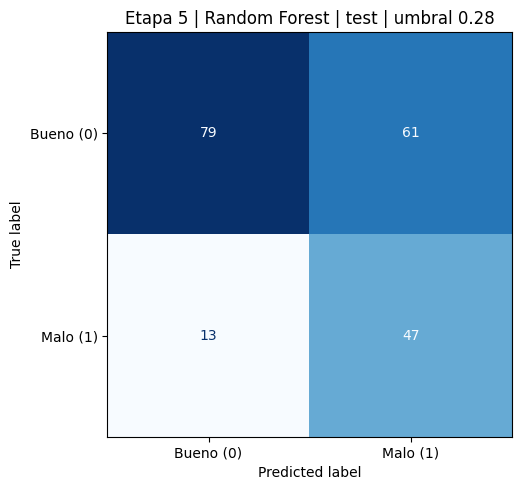

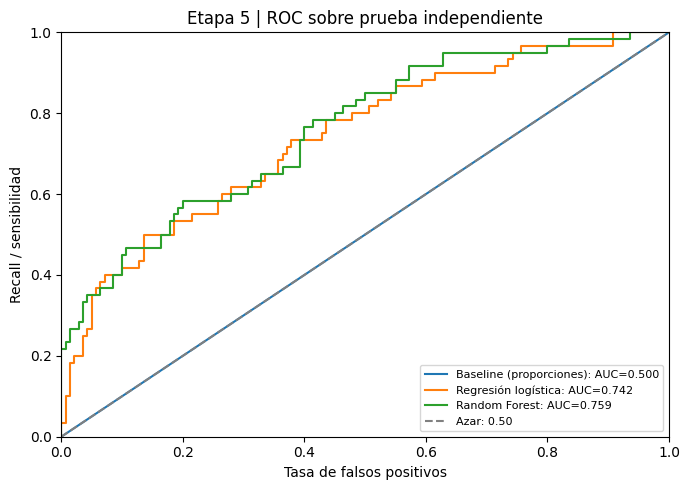

VERIFICACION 5.4: intervalos, matriz y curvas ROC del test guardados.


In [26]:
from math import sqrt

def intervalo_wilson(aciertos, total, z=1.959963984540054):
    if total <= 0:
        return (float('nan'), float('nan'))
    proporcion = aciertos / total
    denom = 1 + z * z / total
    centro = (proporcion + z * z / (2 * total)) / denom
    semiancho = z * sqrt(proporcion * (1-proporcion) / total + z*z/(4*total*total)) / denom
    return (max(0.0, centro-semiancho), min(1.0, centro+semiancho))

fila_final_test = tabla_test.set_index('modelo').loc[MODELO_FINAL_FIJADO]
ci_recall_test = intervalo_wilson(int(fila_final_test['TP']), 60)
ci_especificidad_test = intervalo_wilson(int(fila_final_test['TN']), 140)

rng_test = np.random.default_rng(SEMILLA + 509)
ids_pos_test = np.flatnonzero(y_test_np == 1)
ids_neg_test = np.flatnonzero(y_test_np == 0)
bootstrap_auc_test = np.empty(N_BOOT_TEST)
for i in range(N_BOOT_TEST):
    ids = np.concatenate([
        rng_test.choice(ids_neg_test, len(ids_neg_test), replace=True),
        rng_test.choice(ids_pos_test, len(ids_pos_test), replace=True),
    ])
    bootstrap_auc_test[i] = roc_auc_score(
        y_test_np[ids], probas_test[MODELO_FINAL_FIJADO][ids]
    )
ci_auc_test = np.quantile(bootstrap_auc_test, [0.025, 0.975])

intervalos_test = pd.DataFrame([
    {'metrica':'recall', 'estimacion':float(fila_final_test['recall']),
     'ic95_inferior':ci_recall_test[0], 'ic95_superior':ci_recall_test[1],
     'metodo':'Wilson binomial'},
    {'metrica':'especificidad', 'estimacion':float(fila_final_test['especificidad']),
     'ic95_inferior':ci_especificidad_test[0], 'ic95_superior':ci_especificidad_test[1],
     'metodo':'Wilson binomial'},
    {'metrica':'roc_auc', 'estimacion':float(fila_final_test['roc_auc']),
     'ic95_inferior':float(ci_auc_test[0]), 'ic95_superior':float(ci_auc_test[1]),
     'metodo':'Bootstrap estratificado, modelo fijo'},
])
intervalos_test.to_csv(SALIDA / 'etapa5_intervalos_candidato.csv', index=False)
print('INTERVALOS DEL CANDIDATO (95%)')
print(intervalos_test.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(6.1, 5.0))
matriz_final = confusion_matrix(y_test_np, pred_test[MODELO_FINAL_FIJADO], labels=[0, 1])
ConfusionMatrixDisplay(matriz_final, display_labels=['Bueno (0)', 'Malo (1)']).plot(
    ax=ax, cmap='Blues', colorbar=False, values_format='d')
ax.set_title('Etapa 5 | Random Forest | test | umbral 0.28')
fig.tight_layout()
fig.savefig(SALIDA / 'etapa5_matriz_confusion_test.png', dpi=180, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(7,5))
for nombre in modelos_test_fijos:
    fpr, tpr, _ = roc_curve(y_test_np, probas_test[nombre])
    auc = roc_auc_score(y_test_np, probas_test[nombre])
    ax.plot(fpr, tpr, label=f'{nombre}: AUC={auc:.3f}')
ax.plot([0,1],[0,1],ls='--',color='gray',label='Azar: 0.50')
ax.set(xlabel='Tasa de falsos positivos',ylabel='Recall / sensibilidad',
       title='Etapa 5 | ROC sobre prueba independiente',xlim=(0,1),ylim=(0,1))
ax.legend(loc='lower right', fontsize=8)
fig.tight_layout()
fig.savefig(SALIDA / 'etapa5_roc_test.png', dpi=180, bbox_inches='tight')
plt.show()
print('VERIFICACION 5.4: intervalos, matriz y curvas ROC del test guardados.')

### 5.5 | Cumplimiento SMART y dictamen

*Decisión de aprobacion o no aprobacion.*

In [27]:
metas_test = {
    'recall': float(fila_final_test['recall']) >= METAS['recall'],
    'especificidad': float(fila_final_test['especificidad']) >= METAS['especificidad'],
    'roc_auc': float(fila_final_test['roc_auc']) >= METAS['roc_auc'],
}
limites_inferiores = {r['metrica']: float(r['ic95_inferior'])
                     for _,r in intervalos_test.iterrows()}
cumplimiento_ic_inferior = {k: limites_inferiores[k] >= METAS[k] for k in METAS}
print('METAS SOBRE ESTIMACIONES PUNTUALES:')
for k, v in metas_test.items():
    print(f'  {k}: {"CUMPLE" if v else "NO CUMPLE"} | valor={float(fila_final_test[k]):.3f} | meta={METAS[k]:.2f}')
print('Cumple simultaneamente todas las metas puntuales:', all(metas_test.values()))
print('LIMITES INFERIORES DE IC 95% (lectura prudencial, no regla original de seleccion):')
for k, v in cumplimiento_ic_inferior.items():
    print(f'  {k}: {"supera" if v else "no supera"} el minimo | limite inferior={limites_inferiores[k]:.3f}')
print('Dictamen para uso bancario real: NO APROBADO. Falta validacion externa,')
print('  analisis de sesgos, representatividad, controles y validacion de costos reales.')
print('No ajustar umbrales ni reelegir modelo con base en esta prueba.')
print('VERIFICACION 5.5: dictamen fundamentado registrado sin ajuste post-test.')

METAS SOBRE ESTIMACIONES PUNTUALES:
  recall: CUMPLE | valor=0.783 | meta=0.75
  especificidad: NO CUMPLE | valor=0.564 | meta=0.60
  roc_auc: CUMPLE | valor=0.759 | meta=0.70
Cumple simultaneamente todas las metas puntuales: False
LIMITES INFERIORES DE IC 95% (lectura prudencial, no regla original de seleccion):
  recall: no supera el minimo | limite inferior=0.664
  especificidad: no supera el minimo | limite inferior=0.482
  roc_auc: no supera el minimo | limite inferior=0.687
Dictamen para uso bancario real: NO APROBADO. Falta validacion externa,
  analisis de sesgos, representatividad, controles y validacion de costos reales.
No ajustar umbrales ni reelegir modelo con base en esta prueba.
VERIFICACION 5.5: dictamen fundamentado registrado sin ajuste post-test.


### 5.6 | Registro de evaluación independiente

*Resultados, archivos y trazabilidad.*

In [28]:
registro_5 = {
    'etapa': 5,
    'descripcion': 'Evaluacion interna final sobre test reservado (una sola consulta)',
    'dataset': 'South German Credit, UCI 573',
    'semilla': int(SEMILLA),
    'entrenamiento_n': int(len(X_desarrollo)),
    'prueba_n': int(len(X_prueba)),
    'positivos_test': int((y_test_np==1).sum()),
    'clase_positiva': 'credito malo; riesgo_alto=1',
    'modelo_candidato_fijo': MODELO_FINAL_FIJADO,
    'umbral_fijo': float(UMBRAL_FINAL_FIJADO),
    'metas_ex_ante': {k:float(v) for k,v in METAS.items()},
    'metricas_test_candidato': {
        k:float(fila_final_test[k]) for k in
        ['TN','FP','FN','TP','exactitud','recall','especificidad','precision',
         'f1','roc_auc','tasa_alertas','costo_ponderado']},
    'ic95': {r['metrica']: [float(r['ic95_inferior']),float(r['ic95_superior'])]
             for _,r in intervalos_test.iterrows()},
    'cumplimiento_estimaciones_puntuales': {k:bool(v) for k,v in metas_test.items()},
    'cumplimiento_limite_inferior_95': {k:bool(v) for k,v in cumplimiento_ic_inferior.items()},
    'costos_ilustrativos': {'falso_negativo':int(COSTO_FN_ILUSTRATIVO),
                            'falso_positivo':int(COSTO_FP_ILUSTRATIVO)},
    'despliegue_autorizado': False,
    'limitaciones': [
        'Datos historicos: no representan necesariamente la poblacion o cartera actual.',
        'Validacion interna retenida, no externa ni temporal.',
        'Los resultados de seleccion OOF pueden estar afectados por optimismo.',
        'Prueba unica de 200 registros con incertidumbre muestral importante.',
        'No se ha demostrado equidad, estabilidad, calibracion ni utilidad financiera real.',
        'A/B de etapa 4 es una simulacion retrospectiva, no evidencia causal.',
        'El supuesto de costo 5:1 no es una estimacion financiera real.',
    ],
}
(SALIDA / 'etapa5_registro_evaluacion_independiente.json').write_text(
    json.dumps(registro_5, indent=2, ensure_ascii=False),encoding='utf-8'
)
artefactos_5 = [
    'etapa5_predicciones_prueba_reservada.csv',
    'etapa5_metricas_test_independiente.csv',
    'etapa5_intervalos_candidato.csv',
    'etapa5_matriz_confusion_test.png',
    'etapa5_roc_test.png',
    'etapa5_registro_evaluacion_independiente.json',
]
assert all((SALIDA / f).is_file() for f in artefactos_5)
assert not registro_5['despliegue_autorizado']
print('Archivos generados:')
for a in artefactos_5:
    print(' -', a)
print('VERIFICACION 5.6: evaluacion independiente documentada; ningun despliegue aprobado.')

Archivos generados:
 - etapa5_predicciones_prueba_reservada.csv
 - etapa5_metricas_test_independiente.csv
 - etapa5_intervalos_candidato.csv
 - etapa5_matriz_confusion_test.png
 - etapa5_roc_test.png
 - etapa5_registro_evaluacion_independiente.json
VERIFICACION 5.6: evaluacion independiente documentada; ningun despliegue aprobado.


### 5.7 | Control de la Etapa 5

*Verificación del resultado final.*

## ETAPA 6. Tablero y evidencias

*Fase: consolidación visual y preparación de entregables.*

### 6.1 | Integridad y dictamen final

*Resultados congelados, sin reentrenamiento.*

In [29]:
# Este bloque reutiliza los objetos de la Etapa 5; no realiza predict ni fit.
assert MODELO_FINAL_FIJADO == 'Random Forest' and np.isclose(UMBRAL_FINAL_FIJADO, 0.28)
assert len(tabla_test) == 3 and int(matriz_final.sum()) == 200
assert set(intervalos_test['metrica']) == {'recall', 'especificidad', 'roc_auc'}
assert int(fila_final_test['TN'] + fila_final_test['FP']) == 140
assert int(fila_final_test['FN'] + fila_final_test['TP']) == 60
assert int(fila_final_test['FN'] * COSTO_FN_ILUSTRATIVO + fila_final_test['FP'] * COSTO_FP_ILUSTRATIVO) == int(fila_final_test['costo_ponderado'])
assert not registro_5['despliegue_autorizado']
assert np.isclose(float(fila_final_test['recall']), int(fila_final_test['TP'])/60)
assert np.isclose(float(fila_final_test['especificidad']), int(fila_final_test['TN'])/140)

aprobado_smart = all(bool(v) for v in metas_test.values())
dictamen_estudio = 'CUMPLE LAS 3 METAS PUNTUALES' if aprobado_smart else 'NO CUMPLE LAS 3 METAS PUNTUALES'
dictamen_uso = 'NO APROBADO PARA USO BANCARIO REAL'
comparador_test = tabla_test.set_index('modelo')
print('MODELO Y UMBRAL FIJADOS:', MODELO_FINAL_FIJADO, UMBRAL_FINAL_FIJADO)
print('MATRIZ TEST | TN:', int(fila_final_test['TN']), '| FP:', int(fila_final_test['FP']), '| FN:', int(fila_final_test['FN']), '| TP:', int(fila_final_test['TP']))
print('OBJETIVO SMART:', dictamen_estudio)
print('USO BANCARIO REAL:', dictamen_uso)
print('Verificaciones individuales:', metas_test)
print('VERIFICACIÓN 6.1: métricas y dictamen consolidados, sin cambios del modelo.')

MODELO Y UMBRAL FIJADOS: Random Forest 0.28
MATRIZ TEST | TN: 79 | FP: 61 | FN: 13 | TP: 47
OBJETIVO SMART: NO CUMPLE LAS 3 METAS PUNTUALES
USO BANCARIO REAL: NO APROBADO PARA USO BANCARIO REAL
Verificaciones individuales: {'recall': True, 'especificidad': False, 'roc_auc': True}
VERIFICACIÓN 6.1: métricas y dictamen consolidados, sin cambios del modelo.


### 6.2 | Tablero ejecutivo

*Métricas, matriz, A/B y dictamen.*

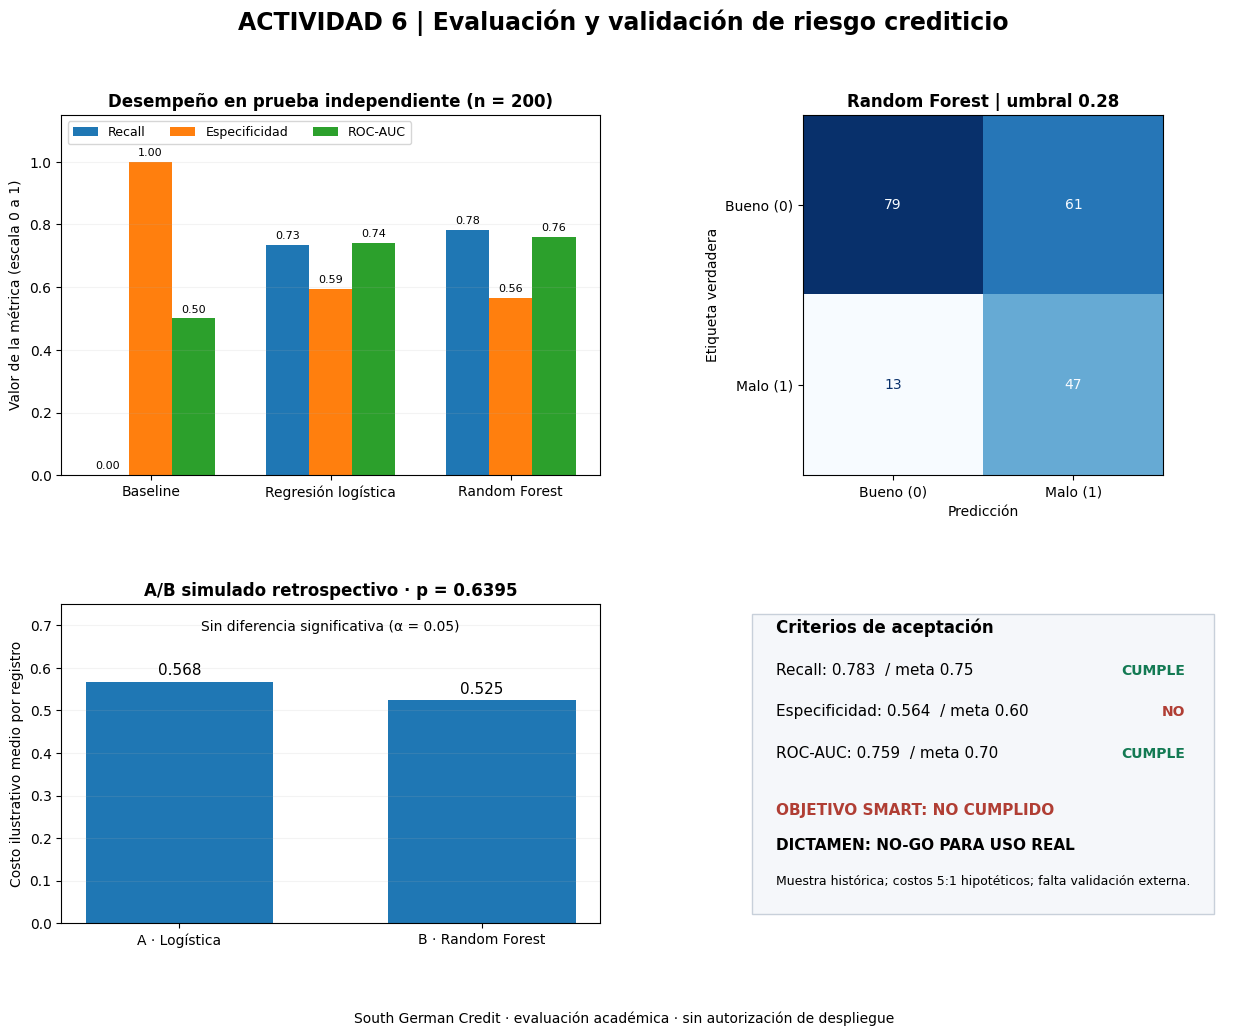

Tablero creado: actividad6_resultados/etapa6_tablero_ejecutivo.png
VERIFICACIÓN 6.2: tablero comparativo reproducible generado.


In [30]:
from matplotlib.patches import Rectangle

fig = plt.figure(figsize=(15, 10.5), facecolor='white')
reja = fig.add_gridspec(2, 2, height_ratios=[1.13, 1], width_ratios=[1.12, 1], hspace=0.38, wspace=0.28)

# Comparación de desempeño en test (métricas ya calculadas).
ax1 = fig.add_subplot(reja[0, 0])
orden_nombres = ['Baseline (proporciones)', 'Regresión logística', 'Random Forest']
comparacion = comparador_test.loc[orden_nombres]
posiciones = np.arange(3)
ancho = 0.24
for desplazamiento, metrica, etiqueta in [(-ancho, 'recall','Recall'), (0, 'especificidad','Especificidad'), (ancho,'roc_auc','ROC-AUC')]:
    barras = ax1.bar(posiciones+desplazamiento, comparacion[metrica].to_numpy(), ancho, label=etiqueta)
    for b in barras:
        ax1.annotate(f'{b.get_height():.2f}', (b.get_x()+b.get_width()/2, b.get_height()),
                     ha='center', va='bottom', fontsize=8, xytext=(0, 3), textcoords='offset points')
ax1.set_xticks(posiciones, ['Baseline', 'Regresión logística', 'Random Forest'])
ax1.set_ylim(0, 1.15)
ax1.set_yticks(np.arange(0, 1.01, .2))
ax1.set_title('Desempeño en prueba independiente (n = 200)', fontweight='bold', fontsize=12)
ax1.set_ylabel('Valor de la métrica (escala 0 a 1)')
ax1.legend(fontsize=9, loc='upper left', ncol=3)
ax1.grid(axis='y', alpha=.15)

# Matriz de confusión congelada.
ax2 = fig.add_subplot(reja[0,1])
ConfusionMatrixDisplay(matriz_final, display_labels=['Bueno (0)', 'Malo (1)']).plot(
    ax=ax2, cmap='Blues', colorbar=False, values_format='d')
ax2.set_title('Random Forest | umbral 0.28', fontweight='bold', fontsize=12)
ax2.set_xlabel('Predicción')
ax2.set_ylabel('Etiqueta verdadera')

# Gráfico A/B etiquetado como simulación, no inferencia causal.
ax3 = fig.add_subplot(reja[1,0])
vals_ab = [float(valores_a.mean()), float(valores_b.mean())]
bars = ax3.bar(['A · Logística', 'B · Random Forest'], vals_ab, width=.62)
for bar, v in zip(bars, vals_ab):
    ax3.text(bar.get_x()+bar.get_width()/2, v+.015, f'{v:.3f}', ha='center', fontsize=11)
ax3.set_ylim(0, max(vals_ab)*1.32)
ax3.set_ylabel('Costo ilustrativo medio por registro')
ax3.set_title(f'A/B simulado retrospectivo · p = {p_ab:.4f}', fontweight='bold', fontsize=12)
ax3.text(.5, .95, 'Sin diferencia significativa (α = 0.05)', ha='center', va='top',
         transform=ax3.transAxes, fontsize=10)
ax3.grid(axis='y', alpha=.15)

# Tarjeta de dictamen reproducible.
ax4 = fig.add_subplot(reja[1,1])
ax4.axis('off')
ax4.add_patch(Rectangle((0.02,0.03),.96,.94,transform=ax4.transAxes,
                         facecolor='#F5F7FA',edgecolor='#C8D0DA',linewidth=1))
rf = comparador_test.loc['Random Forest']
filas_estado = [
    ('Recall', rf['recall'], METAS['recall']),
    ('Especificidad', rf['especificidad'], METAS['especificidad']),
    ('ROC-AUC', rf['roc_auc'], METAS['roc_auc'])]
ax4.text(.07,.91,'Criterios de aceptación',transform=ax4.transAxes,fontsize=12,fontweight='bold')
for iy,(etiqueta,valor,meta) in enumerate(filas_estado):
    ok = valor >= meta
    ax4.text(.07,.78-iy*.13, f'{etiqueta}: {valor:.3f}  / meta {meta:.2f}',
             transform=ax4.transAxes,fontsize=11)
    ax4.text(.92,.78-iy*.13,'CUMPLE' if ok else 'NO',ha='right',
             transform=ax4.transAxes,fontsize=10,fontweight='bold',
             color='#137A53' if ok else '#B03E34')
ax4.text(.07,.34, 'OBJETIVO SMART: '+('CUMPLIDO' if aprobado_smart else 'NO CUMPLIDO'),
         transform=ax4.transAxes,fontsize=11,fontweight='bold',color='#137A53' if aprobado_smart else '#B03E34')
ax4.text(.07,.23, 'DICTAMEN: NO-GO PARA USO REAL',transform=ax4.transAxes,fontsize=11,fontweight='bold')
ax4.text(.07,.12, 'Muestra histórica; costos 5:1 hipotéticos; falta validación externa.',
         transform=ax4.transAxes,fontsize=9)
fig.suptitle('ACTIVIDAD 6 | Evaluación y validación de riesgo crediticio',
             fontsize=17,fontweight='bold',y=.98)
fig.text(.5, .015, 'South German Credit · evaluación académica · sin autorización de despliegue',
         ha='center',fontsize=10)
fig.savefig(SALIDA/'etapa6_tablero_ejecutivo.png',dpi=170,bbox_inches='tight',facecolor='white')
plt.show()
print('Tablero creado:', SALIDA/'etapa6_tablero_ejecutivo.png')
print('VERIFICACIÓN 6.2: tablero comparativo reproducible generado.')

### 6.3 | Metas e intervalos de confianza

*Comparación gráfica de objetivos SMART.*

MÉTRICAS DEL CANDIDATO, 95% IC Y CUMPLIMIENTO:
      metrica  valor_test  meta  ic95_inferior  ic95_superior  cumple_meta_puntual  supera_meta_limite_inferior
       recall      0.7833  0.75         0.6638         0.8688                 True                        False
especificidad      0.5643  0.60         0.4815         0.6436                False                        False
      roc_auc      0.7588  0.70         0.6865         0.8268                 True                        False


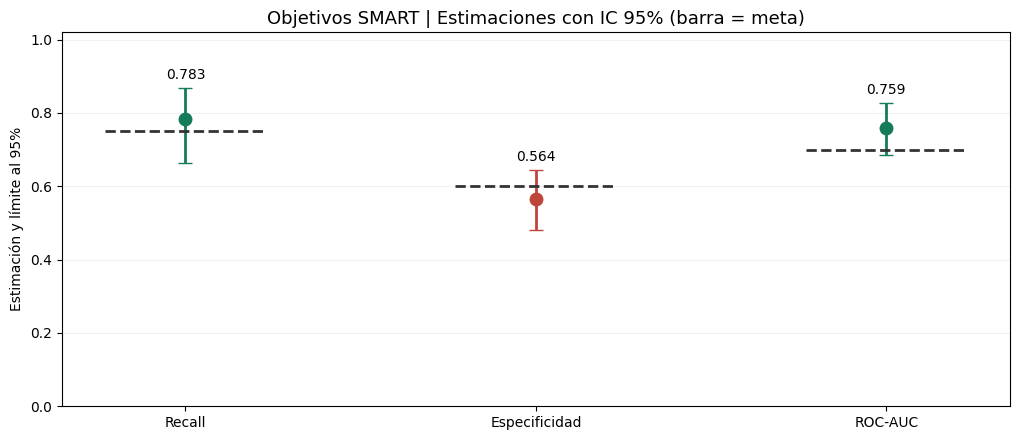

VERIFICACIÓN 6.3: control de metas e incertidumbre generado.


In [31]:
lineas = []
for metrica in ['recall','especificidad','roc_auc']:
    fila_ci = intervalos_test.set_index('metrica').loc[metrica]
    valor = float(fila_ci['estimacion']); meta = float(METAS[metrica]); inf = float(fila_ci['ic95_inferior']); sup = float(fila_ci['ic95_superior'])
    lineas.append({'metrica':metrica, 'valor_test':valor, 'meta':meta,
                   'ic95_inferior':inf, 'ic95_superior':sup, 'cumple_meta_puntual':bool(valor>=meta),
                   'supera_meta_limite_inferior':bool(inf>=meta)})
resumen_metas_6 = pd.DataFrame(lineas)
resumen_metas_6.to_csv(SALIDA/'etapa6_metas_e_intervalos.csv',index=False)
print('MÉTRICAS DEL CANDIDATO, 95% IC Y CUMPLIMIENTO:')
print(resumen_metas_6.round(4).to_string(index=False))

fig, ax = plt.subplots(figsize=(10.3,4.5))
orden = ['recall','especificidad','roc_auc']; posicion = np.arange(3)
for j,met in enumerate(orden):
    d = resumen_metas_6.set_index('metrica').loc[met]
    col = '#167b5b' if bool(d['cumple_meta_puntual']) else '#be4539'
    ax.errorbar(j,float(d['valor_test']),
       yerr=[[float(d['valor_test']-d['ic95_inferior'])],[float(d['ic95_superior']-d['valor_test'])]],
       fmt='o',markersize=9,color=col,capsize=5,linewidth=2)
    ax.hlines(float(d['meta']),j-.23,j+.23,colors='#333333',linestyle='dashed',linewidth=2)
    ax.text(j,float(d['ic95_superior'])+.025,f"{float(d['valor_test']):.3f}",ha='center',fontsize=10)
ax.set_xticks(posicion,['Recall','Especificidad','ROC-AUC'])
ax.set_ylim(0,1.02)
ax.set_ylabel('Estimación y límite al 95%')
ax.set_title('Objetivos SMART | Estimaciones con IC 95% (barra = meta)',fontsize=13)
ax.grid(axis='y',alpha=.17)
fig.tight_layout()
fig.savefig(SALIDA/'etapa6_metas_vs_intervalos.png',dpi=180,bbox_inches='tight')
plt.show()
print('VERIFICACIÓN 6.3: control de metas e incertidumbre generado.')

### 6.4 | Guia para Trello

*Seis tarjetas y evidencias asociadas.*

In [32]:
tarjetas = [
  {'titulo':'01 · Problema, datos y objetivo SMART',
   'imagen':'etapa1_distribucion_clases.png',
   'texto':'1,000 registros; 700 créditos buenos y 300 malos. Clase positiva = crédito malo. Criterios: recall ≥ 0.75, especificidad ≥ 0.60, ROC-AUC ≥ 0.70.'},
  {'titulo':'02 · Validación cruzada y comparación de modelos',
   'imagen':'etapa2_comparacion_roc_auc_cv.png',
   'texto':'Cinco folds estratificados sobre desarrollo (800 observaciones). Baseline, regresión logística y Random Forest. No se usa el test en la selección.'},
  {'titulo':'03 · Umbral, ROC y matrices de confusión',
   'imagen':'etapa3_matriz_seleccionado.png',
   'texto':'Random Forest con umbral 0.28 seleccionado en desarrollo OOF. Distinguir optimización retrospectiva de validación independiente.'},
  {'titulo':'04 · Significancia y A/B simulado',
   'imagen':'etapa4_ab_costos_medios.png',
   'texto':f'Prueba A/B retrospectiva, dos grupos de 400; p={p_ab:.4f}. No hay evidencia de diferencia significativa ni efecto causal demostrado.'},
  {'titulo':'05 · Resultado independiente y decisión',
   'imagen':'etapa6_tablero_ejecutivo.png',
   'texto':f"Random Forest, umbral 0.28: recall={float(rf['recall']):.3f}, especificidad={float(rf['especificidad']):.3f}, ROC-AUC={float(rf['roc_auc']):.3f}. {'Cumple' if aprobado_smart else 'No cumple'} todas las metas. Decisión: no aprobar despliegue."},
  {'titulo':'06 · Evidencias, limitaciones y siguientes pasos',
   'imagen':'etapa6_metas_vs_intervalos.png',
   'texto':'Falta representatividad contemporánea, validación temporal/externa, análisis de sesgos y costos observables. Mantener revisión humana obligatoria.'},
]

lineas_trello = [
 '# Actividad 6 — Guía de carga en Trello',
 '',
 'Tablero propuesto: Evaluación y validación | Riesgo crediticio',
 'Crear seis tarjetas con las siguientes descripciones y adjuntar las imágenes indicadas.',
 'Entregar el enlace al tablero o capturas en PDF. Esta guía no sustituye el tablero real.',
 '']
for t in tarjetas:
    lineas_trello += [f"## {t['titulo']}", '',t['texto'],f"Imagen para adjuntar: `{t['imagen']}`",'']
lineas_trello += [
 '## Nota metodológica',
 'El test independiente se consultó en Etapa 5 con modelos y umbrales fijados previamente.',
 'La especificidad del candidato no alcanzó el mínimo originalmente establecido.',
 'La prueba A/B es una simulación retrospectiva y no un experimento de negocio en producción.',
 'Las unidades de costo son hipotéticas; no representan pesos ni pérdidas observadas.']
(SALIDA/'etapa6_guia_trello.md').write_text('\n'.join(lineas_trello)+'\n',encoding='utf-8')

resumen_dictamen = {
  'modelo':MODELO_FINAL_FIJADO,'umbral':float(UMBRAL_FINAL_FIJADO),
  'n_test':int(len(y_test_np)),
  'metricas':{m:float(fila_final_test[m]) for m in ['exactitud','recall','especificidad','precision','f1','roc_auc','costo_ponderado']},
  'metas':{k:float(v) for k,v in METAS.items()},
  'cumplimiento_smart_puntual':bool(aprobado_smart),
  'despliegue_autorizado':False,
  'ab_simulado_p':float(p_ab),
  'ab_simulado_significativo_alpha_005':bool(p_ab<.05),
  'costo_fn_fp':'5 a 1: exclusivamente ilustrativo',
  'recomendacion':'No-go. No reoptimizar con el test; cualquier nueva versión requiere diseño prospectivo y nueva muestra independiente.',
  'limitaciones':registro_5['limitaciones']
}
(SALIDA/'etapa6_dictamen_final.json').write_text(json.dumps(resumen_dictamen,ensure_ascii=False,indent=2),encoding='utf-8')
print('Tarjetas preparadas para Trello:',len(tarjetas))
print('Decisión:',resumen_dictamen['recomendacion'])
print('VERIFICACIÓN 6.4: guía y dictamen generados; Trello requiere carga real.')

Tarjetas preparadas para Trello: 6
Decisión: No-go. No reoptimizar con el test; cualquier nueva versión requiere diseño prospectivo y nueva muestra independiente.
VERIFICACIÓN 6.4: guía y dictamen generados; Trello requiere carga real.


### 6.5 | Inventario y respaldo ZIP

*Verificación y empaquetado de archivos.*

In [33]:
import zipfile as _zipfile
archivos_requeridos = [
 'etapa1_distribucion_clases.png',
 'etapa2_comparacion_roc_auc_cv.png',
 'etapa3_matriz_seleccionado.png',
 'etapa4_ab_costos_medios.png',
 'etapa5_matriz_confusion_test.png',
 'etapa5_roc_test.png',
 'etapa5_metricas_test_independiente.csv',
 'etapa5_intervalos_candidato.csv',
 'etapa5_registro_evaluacion_independiente.json',
 'etapa6_tablero_ejecutivo.png',
 'etapa6_metas_vs_intervalos.png',
 'etapa6_metas_e_intervalos.csv',
 'etapa6_guia_trello.md',
 'etapa6_dictamen_final.json',
]
faltantes = [archivo for archivo in archivos_requeridos if not (SALIDA/archivo).is_file()]
assert not faltantes, f'Faltan evidencias: {faltantes}'

inventario = []
for ruta in sorted(SALIDA.iterdir()):
    if ruta.is_file() and ruta.name!='etapa6_inventario_archivos.csv':
        inventario.append({'archivo':ruta.name,'tamano_bytes':int(ruta.stat().st_size),
                           'sha256':hashlib.sha256(ruta.read_bytes()).hexdigest()})
pd.DataFrame(inventario).to_csv(SALIDA/'etapa6_inventario_archivos.csv',index=False)
respaldo = Path('Actividad_6_Evidencias_Colab.zip')
with _zipfile.ZipFile(respaldo,'w',compression=_zipfile.ZIP_DEFLATED) as z:
    for ruta in sorted(SALIDA.iterdir()):
        if ruta.is_file():
            z.write(ruta,arcname='actividad6_resultados/'+ruta.name)
assert respaldo.exists() and respaldo.stat().st_size>0
print('Archivos de evidencia inventariados:',len(inventario))
print('Respaldo generado:',respaldo.resolve())
print('Atención: para calificación falta crear tablero Trello real y subir notebook/documentación al repositorio GitHub.')
print('VERIFICACIÓN 6.5: inventario y respaldo generados sin modificar los modelos.')

Archivos de evidencia inventariados: 30
Respaldo generado: /content/Actividad_6_Evidencias_Colab.zip
Atención: para calificación falta crear tablero Trello real y subir notebook/documentación al repositorio GitHub.
VERIFICACIÓN 6.5: inventario y respaldo generados sin modificar los modelos.


### 6.6 | Descargar respaldo ZIP

*Ejecuta la celda siguiente para iniciar la descarga.*

In [34]:
# Descarga directa al ejecutar esta celda en Google Colab.
from pathlib import Path

archivo_zip = Path('Actividad_6_Evidencias_Colab.zip')
assert archivo_zip.is_file() and archivo_zip.stat().st_size > 0, (
    'El ZIP aun no existe. Ejecuta primero la seccion 6.5.'
)
print(f'Archivo listo: {archivo_zip.name} ({archivo_zip.stat().st_size:,} bytes)')

try:
    from google.colab import files as archivos_colab
except ImportError:
    print('Descarga automatica disponible en Google Colab.')
    print('Ubicacion local:', archivo_zip.resolve())
else:
    archivos_colab.download(str(archivo_zip))


Archivo listo: Actividad_6_Evidencias_Colab.zip (855,531 bytes)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>